# 3. Complete CCLE model comparison and barplots

This notebook creates one reproducible comparison of:

- three same-gene baselines: raw RNA, train-only z-score mapping, and train-fitted linear regression;
- ElasticNet and XGBoost runs from `results_enet/`, `res_enet_zbig/`, `results_xgb/`, and `res_xgb_zbig/`;
- scTranslator checkpoint 10K from `sc_predictions_10K.npz` when that file contains predictions and either matching targets or enough labels to align predictions to the proteomics matrix.

**Headline figure.** Section 10 reports every model inside a single matched evaluation scope: the same held-out
test samples and the same proteins for all models. scTranslator is re-scored from its stored predictions inside
that scope rather than being compared on its own, larger evaluation set. This is the comparison to quote, because
it is the only one in which the means are strictly commensurable.

The notebook is designed for the directory shown in the project screenshot. It can be launched from the project root or a nearby parent/child directory. Data files are discovered from the project root, `data/`, `src/`, and the parent `data/` directory. Result tables in `procedural_tables/` are used when available; otherwise HDF5 artifacts are scanned directly.

All output is written to `complete_comparison_outputs/`. The manifest records whether the exact saved test split was recovered or whether the explicitly labelled deterministic fallback split had to be used.


In [1]:
from __future__ import annotations

from pathlib import Path
import hashlib
import json
import math
import re
import warnings

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)

# ------------------------------------------------------------------
# User configuration. Normally these can remain None.
# ------------------------------------------------------------------
PROJECT_ROOT_OVERRIDE = None
X_PATH_OVERRIDE = None
Y_PATH_OVERRIDE = None
MODEL_METRICS_PATHS = []
SCTRANSLATOR_METRICS_PATH_OVERRIDE = None
SCTRANSLATOR_PREDICTIONS_PATH_OVERRIDE = None

SAVE_FIGURES = True
SAVE_TABLES = True
PNG_DPI = 400
RANDOM_SEED = 42
BOOTSTRAP_REPLICATES = 1000

# Used only when no saved split can be recovered. The fallback is clearly
# labelled in printed output and in the manifest; it is never presented as exact.
ALLOW_DETERMINISTIC_SPLIT_FALLBACK = True
FALLBACK_TEST_FRACTION = 0.20

# ------------------------------------------------------------------
# Matched-scope comparison.
# scTranslator is re-scored on exactly the held-out test samples and on the
# proteins that the other models were evaluated on, so that every mean in the
# headline bar plot refers to the same evaluation scope.
# ------------------------------------------------------------------
USE_PROCEDURAL_TABLES = False       # results come from the results_* folders only
MATCHED_SCOPE_MIN_PROTEINS = 5      # below this, the protein rule relaxes to the union
MATCHED_SCOPE_INCLUDE_R2 = False    # R2 is reported in the table but kept out of the bar panels
BAR_LOG_SCALE_RATIO = 8.0           # log-scale a bar panel when one model dominates the range; 0 disables

RESULT_DIR_NAMES = ["results_enet", "res_enet_zbig", "results_xgb", "res_xgb_zbig"]


def _project_score(path: Path) -> int:
    if not path.exists() or not path.is_dir():
        return -1
    score = 10 * sum((path / name).is_dir() for name in RESULT_DIR_NAMES)
    score += 3 * int((path / "procedural_tables").is_dir())
    score += 2 * int((path / "sc_predictions_10K.npz").is_file())
    score += int(any(path.glob("*complete_comparison*.ipynb")))
    return score


def find_project_root(start: Path) -> Path:
    if PROJECT_ROOT_OVERRIDE is not None:
        root = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
        if not root.exists():
            raise FileNotFoundError(f"PROJECT_ROOT_OVERRIDE does not exist: {root}")
        return root

    start = start.expanduser().resolve()
    candidates = []
    for parent in [start, *start.parents[:5]]:
        candidates.append(parent)
        try:
            candidates.extend(p for p in parent.iterdir() if p.is_dir())
        except OSError:
            pass

    unique = []
    seen = set()
    for candidate in candidates:
        key = str(candidate)
        if key not in seen:
            seen.add(key)
            unique.append(candidate)

    best = max(unique, key=_project_score)
    return best if _project_score(best) > 0 else start


ROOT = find_project_root(Path.cwd())
OUTPUT_DIR = ROOT / "complete_comparison_outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

MODEL_DIRS = {
    "enet": ROOT / "results_enet",
    "enet_zbig": ROOT / "res_enet_zbig",
    "xgb": ROOT / "results_xgb",
    "xgb_zbig": ROOT / "res_xgb_zbig",
}

print("Project root:", ROOT)
print("Output directory:", OUTPUT_DIR)
for key, path in MODEL_DIRS.items():
    print(f"{key:10s}: {path} | exists={path.exists()}")


Project root: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison
Output directory: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\complete_comparison_outputs
enet      : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_enet | exists=True
enet_zbig : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_enet_zbig | exists=True
xgb       : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\results_xgb | exists=True
xgb_zbig  : C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\res_xgb_zbig | exists=True


## 1. Helper functions

The helpers below are self-contained. They read the minimal metrics and split metadata from the saved H5 artifacts, compute the three same-gene baselines, standardize model names, summarize distributions, and save figures consistently.


In [2]:
def require_file(path: Path | None, label: str = "file") -> Path:
    if path is None:
        raise FileNotFoundError(f"Could not discover the required {label}.")
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required {label} not found: {path.resolve()}")
    return path


def _limited_rglob(root: Path, filename: str, max_depth: int = 4) -> list[Path]:
    if not root.exists() or not root.is_dir():
        return []
    matches = []
    try:
        for path in root.rglob(filename):
            try:
                depth = len(path.relative_to(root).parts)
            except ValueError:
                continue
            if depth <= max_depth:
                matches.append(path)
    except OSError:
        pass
    return matches


def discover_named_file(override, names, label: str) -> Path | None:
    if override is not None:
        path = Path(override).expanduser()
        if not path.is_absolute():
            path = ROOT / path
        return require_file(path.resolve(), label)

    roots = [ROOT / "data", ROOT, ROOT / "src", ROOT.parent / "data"]
    for base in roots:
        for name in names:
            candidate = base / name
            if candidate.is_file():
                return candidate.resolve()

    for name in names:
        for candidate in _limited_rglob(ROOT, name, max_depth=4):
            if OUTPUT_DIR not in candidate.parents:
                return candidate.resolve()
    return None


def load_dataframe(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix in {".joblib", ".pkl", ".pickle"}:
        obj = joblib.load(path)
    elif suffix == ".parquet":
        obj = pd.read_parquet(path)
    elif suffix == ".feather":
        obj = pd.read_feather(path)
    elif suffix in {".csv", ".tsv"}:
        obj = pd.read_csv(path, sep="\t" if suffix == ".tsv" else ",", index_col=0)
    else:
        raise ValueError(f"Unsupported table format: {path}")

    if isinstance(obj, pd.DataFrame):
        return obj.copy()
    if isinstance(obj, dict):
        if {"data", "index", "columns"}.issubset(obj):
            return pd.DataFrame(obj["data"], index=obj["index"], columns=obj["columns"])
        for value in obj.values():
            if isinstance(value, pd.DataFrame):
                return value.copy()
    raise TypeError(f"{path} did not contain a pandas DataFrame (found {type(obj)}).")


def _as_scalar(value):
    if isinstance(value, bytes):
        return value.decode("utf-8", errors="replace")
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        if value.shape == ():
            return _as_scalar(value.item())
        if value.size == 1:
            return _as_scalar(value.reshape(-1)[0])
    return value


def _decode_index(value) -> pd.Index:
    arr = np.asarray(value)
    if arr.shape == ():
        arr = np.asarray([arr.item()])
    return pd.Index([str(_as_scalar(v)) for v in arr.reshape(-1)])


def _normalized_key(value) -> str:
    return re.sub(r"[^a-z0-9]+", "", str(value).lower())


def _h5_items(h5):
    items = []
    h5.visititems(lambda name, obj: items.append((name, obj)))
    return items


def _find_h5_attr(h5, names):
    wanted = {_normalized_key(n) for n in names}
    objects = [h5] + [obj for _, obj in _h5_items(h5) if hasattr(obj, "attrs")]
    for obj in objects:
        for key, value in obj.attrs.items():
            if _normalized_key(key) in wanted:
                return _as_scalar(value)
    return None


def _find_h5_dataset(h5, names):
    wanted = {_normalized_key(n) for n in names}
    for name, obj in _h5_items(h5):
        if not isinstance(obj, h5py.Dataset):
            continue
        base = _normalized_key(Path(name).name)
        full = _normalized_key(name)
        if base in wanted or full in wanted or any(full.endswith(item) for item in wanted):
            try:
                return obj[()]
            except Exception:
                continue
    return None


def _find_h5_value(h5, names):
    value = _find_h5_attr(h5, names)
    if value is None:
        value = _find_h5_dataset(h5, names)
    return _as_scalar(value)


def _find_h5_numeric(h5, names):
    value = _find_h5_value(h5, names)
    try:
        return float(value)
    except Exception:
        return np.nan


def canonical_normalization(value) -> str:
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return "unknown"
    text = str(_as_scalar(value)).strip().lower().replace("-", "_").replace(" ", "_")
    if any(token in text for token in ["qbin", "quantile", "bin50"]):
        return "qbin50"
    if "rank" in text or "percentile" in text:
        return "rank"
    if any(token in text for token in ["zscore", "z_score", "standardize", "standardized"]):
        return "zscore"
    if text in {"z", "standard"}:
        return "zscore"
    if text in {"no", "raw", "identity", "none", "untransformed"}:
        return "none"
    if set(re.split(r"[^a-z0-9]+", text)).intersection(
        {"no", "raw", "identity", "none", "untransformed", "notransform"}
    ):
        return "none"
    return text


def infer_family(value) -> str:
    text = str(value).lower()
    if "elastic" in text or "enet" in text:
        return "enet"
    if "xgboost" in text or "xgb" in text:
        return "xgb"
    return "unknown"


def infer_select_k(value, source="") -> float:
    text = f"{value} {source}".lower().replace(",", "")
    match = re.search(r"(?:^|[^0-9])(?:k|top|select)[_\- ]?(\d{3,6})(?:[^0-9]|$)", text)
    if match:
        return float(match.group(1))
    for k in (5000, 2000):
        if re.search(rf"(?:^|[^0-9]){k}(?:[^0-9]|$)", text):
            return float(k)
    if "zbig" in text:
        return 5000.0
    if any(name in text for name in ["results_enet", "results_xgb"]):
        return 2000.0
    return np.nan


RUN_TOKEN_PATTERN = (
    r"_(?:elasticnet|enet|xgboost|xgb|zscore|z_score|rank(?:ing)?|qbin50|qbin|quantile|none|raw)(?:_|$)"
)
GRID_PRESETS = ["fast", "current", "full", "tiny"]


def parse_h5_name(path: Path, source: str) -> dict:
    """Parse run metadata from a result filename.

    The protein symbol is stripped off *before* any run metadata is inferred,
    and the grid preset is matched against whole underscore-delimited tokens
    rather than raw substrings. Protein symbols routinely contain the same
    substrings as the run tokens - FASTKD2 contains "fast", TRANK1 and RANKL
    contain "rank" - so matching against the whole filename silently mislabels
    those files and can collapse an entire run to a handful of proteins.
    """
    stem = path.stem
    protein = re.split(RUN_TOKEN_PATTERN, stem, maxsplit=1, flags=re.IGNORECASE)[0]
    if not protein:
        protein = stem.split("_")[0]

    # Everything after the protein symbol describes the run.
    remainder = stem[len(protein):].lower()
    if not remainder.strip("_"):
        remainder = stem.lower()
    tokens = {token for token in re.split(r"[^a-z0-9]+", remainder) if token}

    family = infer_family(f"{remainder} {source}")
    norm = canonical_normalization(remainder)
    if norm not in {"none", "zscore", "rank", "qbin50"}:
        norm = "unknown"

    grid = next((preset for preset in GRID_PRESETS if preset in tokens), "unknown")
    select_k = infer_select_k(remainder, source)

    return {
        "protein": protein,
        "family": family,
        "source_folder": source,
        "normalization": norm,
        "grid_preset": grid,
        "select_k": select_k,
    }


def load_h5_summary(path: Path, source: str) -> dict:
    row = parse_h5_name(path, source)
    row.update({
        "h5_path": str(path.resolve()),
        "file": path.name,
        "load_error": None,
        "artifact_source": "h5",
    })
    try:
        with h5py.File(path, "r") as h5:
            stored_protein = _find_h5_value(h5, ["protein", "target", "target_protein", "target_gene", "gene"])
            if stored_protein is not None:
                row["protein"] = str(stored_protein)

            stored_family = _find_h5_value(h5, ["family", "model_family", "model_type", "estimator"])
            if stored_family is not None and infer_family(stored_family) != "unknown":
                row["family"] = infer_family(stored_family)

            stored_norm = _find_h5_value(h5, [
                "normalization", "normalization_name", "transform", "transformation", "transform_name"
            ])
            if stored_norm is not None:
                parsed = canonical_normalization(stored_norm)
                if parsed in {"none", "zscore", "rank", "qbin50"}:
                    row["normalization"] = parsed

            stored_k = _find_h5_value(h5, ["select_k", "k", "n_features", "num_features", "top_k"])
            if stored_k is not None:
                try:
                    row["select_k"] = float(stored_k)
                except Exception:
                    pass

            row["pcc"] = _find_h5_numeric(h5, [
                "test_pearson_corr", "test_pearson", "pearson_test", "pearson_corr", "pearson", "pcc"
            ])
            row["mse"] = _find_h5_numeric(h5, ["test_mse", "mse_test", "mean_squared_error", "mse"])
            row["cosine"] = _find_h5_numeric(h5, [
                "test_cosine_similarity", "test_cosine", "cosine_similarity", "cosine"
            ])
            row["r2"] = _find_h5_numeric(h5, ["test_r2", "r2_test", "r2", "test_r2_score", "r_squared"])
            row["train_n"] = _find_h5_numeric(h5, ["train_n", "n_train"])
            row["test_n"] = _find_h5_numeric(h5, ["test_n", "n_test"])
    except Exception as exc:
        row["load_error"] = f"{type(exc).__name__}: {exc}"
    return row


def read_test_samples_from_h5(path: Path, all_samples: pd.Index | None = None):
    name_aliases = [
        "test_samples", "test_sample_names", "test_index", "x_test_index", "y_test_index",
        "test_cell_lines", "test_cell_line_names", "heldout_samples", "held_out_samples",
    ]
    index_aliases = ["test_indices", "test_idx", "idx_test", "test_positions", "heldout_indices"]
    with h5py.File(path, "r") as h5:
        value = _find_h5_attr(h5, name_aliases)
        if value is None:
            value = _find_h5_dataset(h5, name_aliases)
        if value is not None:
            decoded = _decode_index(value)
            if all_samples is not None and decoded.intersection(all_samples).empty:
                numeric = pd.to_numeric(pd.Series(decoded), errors="coerce")
                if numeric.notna().all():
                    positions = numeric.astype(int).to_numpy()
                    if len(positions) and positions.min() >= 0 and positions.max() < len(all_samples):
                        return pd.Index(all_samples.take(positions)), "h5 numeric test positions"
            return decoded, "h5 test sample names"

        value = _find_h5_attr(h5, index_aliases)
        if value is None:
            value = _find_h5_dataset(h5, index_aliases)
        if value is not None and all_samples is not None:
            positions = pd.to_numeric(pd.Series(np.asarray(value).reshape(-1)), errors="coerce")
            if positions.notna().all():
                positions = positions.astype(int).to_numpy()
                if len(positions) and positions.min() >= 0 and positions.max() < len(all_samples):
                    return pd.Index(all_samples.take(positions)), "h5 test positions"
    return None, None


def split_hash(samples) -> str:
    payload = "\n".join(sorted(set(map(str, pd.Index(samples))))).encode("utf-8")
    return hashlib.sha1(payload).hexdigest()[:12]


def clean_pair(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    return y_true[mask], y_pred[mask]


def metric_values(y_true, y_pred) -> dict:
    y_true, y_pred = clean_pair(y_true, y_pred)
    if len(y_true) == 0:
        return {"pcc": np.nan, "mse": np.nan, "cosine": np.nan, "r2": np.nan, "n_test": 0}

    mse_value = float(np.mean((y_true - y_pred) ** 2))
    if len(y_true) > 1 and np.std(y_true) > 0 and np.std(y_pred) > 0:
        pcc_value = float(np.corrcoef(y_true, y_pred)[0, 1])
    else:
        pcc_value = np.nan

    denominator = np.linalg.norm(y_true) * np.linalg.norm(y_pred)
    cosine_value = float(np.dot(y_true, y_pred) / denominator) if denominator > 0 else np.nan

    ss_tot = float(np.sum((y_true - np.mean(y_true)) ** 2))
    ss_res = float(np.sum((y_true - y_pred) ** 2))
    r2_value = float(1.0 - ss_res / ss_tot) if ss_tot > 0 else np.nan
    return {"pcc": pcc_value, "mse": mse_value, "cosine": cosine_value, "r2": r2_value, "n_test": len(y_true)}


def save_figure(fig, stem: str):
    if not SAVE_FIGURES:
        return
    fig.savefig(FIGURE_DIR / f"{stem}.png", dpi=PNG_DPI, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{stem}.pdf", bbox_inches="tight")


def mean_ci(values, seed=RANDOM_SEED, n_boot=BOOTSTRAP_REPLICATES):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(dtype=float)
    if len(values) == 0:
        return np.nan, np.nan, np.nan
    mean = float(values.mean())
    if len(values) == 1 or n_boot <= 0:
        return mean, mean, mean
    rng = np.random.default_rng(seed)
    boot = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        boot[i] = rng.choice(values, size=len(values), replace=True).mean()
    return mean, float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975))


def first_matching_column(columns, aliases):
    normalized = {_normalized_key(c): c for c in columns}
    for alias in aliases:
        key = _normalized_key(alias)
        if key in normalized:
            return normalized[key]
    for column in columns:
        key = _normalized_key(column)
        if any(_normalized_key(alias) in key for alias in aliases):
            return column
    return None


FAMILY_COLORS = {
    "Proxy": "#4C78A8",
    "ElasticNet": "#59A14F",
    "XGBoost": "#F28E2B",
    "scTranslator": "#B07AA1",
}

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": PNG_DPI,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "grid.linewidth": 0.7,
    "legend.frameon": False,
})


## 2. Load matched CCLE data


In [3]:
X_PATH = discover_named_file(
    X_PATH_OVERRIDE,
    [
        "transcriptomics_filtered.joblib", "transcriptomics.joblib", "ccle_transcriptomics.joblib",
        "transcriptomics_filtered.pkl", "transcriptomics.parquet",
    ],
    "transcriptomics matrix",
)
Y_PATH = discover_named_file(
    Y_PATH_OVERRIDE,
    [
        "proteomics_matched.joblib", "proteomics.joblib", "ccle_proteomics.joblib",
        "proteomics_matched.pkl", "proteomics.parquet",
    ],
    "proteomics matrix",
)

require_file(X_PATH, "transcriptomics matrix")
require_file(Y_PATH, "proteomics matrix")
print("Transcriptomics source:", X_PATH)
print("Proteomics source:     ", Y_PATH)

X_raw = load_dataframe(X_PATH)
Y_raw = load_dataframe(Y_PATH)

X = X_raw.copy()
Y0 = Y_raw.copy()
X.index = X.index.map(str)
X.columns = X.columns.map(str)
Y0.index = Y0.index.map(str)
Y0.columns = Y0.columns.map(str)

# Detect proteomics orientation and standardize to samples x proteins.
x_samples = set(X.index)
overlap_rows = len(x_samples.intersection(Y0.index))
overlap_columns = len(x_samples.intersection(Y0.columns))
if overlap_rows >= overlap_columns:
    Y = Y0.copy()
    orientation = "samples x proteins"
else:
    Y = Y0.T.copy()
    orientation = "proteins x samples (transposed)"

Y.index = Y.index.map(str)
Y.columns = Y.columns.map(str)
common_samples = X.index.intersection(Y.index, sort=False)
if len(common_samples) < 3:
    raise RuntimeError(
        f"Only {len(common_samples)} sample identifiers overlap between transcriptomics and proteomics. "
        "Check the selected data files and their orientation."
    )

X = X.loc[common_samples].copy()
Y = Y.loc[common_samples].copy()

print("Transcriptomics:", X.shape, "(samples x genes)")
print("Proteomics:     ", Y.shape, "(samples x proteins)")
print("Original proteomics orientation:", orientation)
print("Common samples:", len(common_samples))
print("Exact same-name gene/protein pairs:", len(set(X.columns).intersection(Y.columns)))


Transcriptomics source: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data\transcriptomics_filtered.joblib
Proteomics source:      C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\data\proteomics_matched.joblib
Transcriptomics: (369, 22614) (samples x genes)
Proteomics:      (369, 5113) (samples x proteins)
Original proteomics orientation: samples x proteins
Common samples: 369
Exact same-name gene/protein pairs: 4843


## 3. Load the requested ElasticNet and XGBoost runs

The notebook first looks for the cached summary generated by the earlier comparison notebook. If the cache is not present, it scans the H5 files directly. Only the requested $k=2{,}000$ runs and the two z-score $k=5{,}000$ runs are retained.


In [4]:
def _read_metric_table(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\t")
    if suffix == ".parquet":
        return pd.read_parquet(path)
    if suffix == ".feather":
        return pd.read_feather(path)
    if suffix in {".joblib", ".pkl", ".pickle"}:
        obj = joblib.load(path)
        if isinstance(obj, pd.DataFrame):
            return obj.copy()
        if isinstance(obj, dict):
            return pd.DataFrame(obj)
    raise TypeError(f"Unsupported metrics table: {path}")


def _resolve_h5_reference(value, table_path: Path) -> str:
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return ""
    candidate = Path(str(value)).expanduser()
    checks = [candidate]
    if not candidate.is_absolute():
        checks.extend([table_path.parent / candidate, ROOT / candidate])
    for check in checks:
        if check.is_file():
            return str(check.resolve())
    basename = candidate.name
    if basename:
        for folder in MODEL_DIRS.values():
            matches = list(folder.rglob(basename)) if folder.exists() else []
            if matches:
                return str(matches[0].resolve())
    return str(value)


def standardize_metric_table(raw: pd.DataFrame, path: Path) -> pd.DataFrame:
    if raw.empty:
        return pd.DataFrame()

    protein_col = first_matching_column(raw.columns, [
        "protein", "target_protein", "target_gene", "gene", "protein_name", "target"
    ])
    if protein_col is None:
        unnamed = [c for c in raw.columns if str(c).lower().startswith("unnamed")]
        if unnamed and raw[unnamed[0]].nunique(dropna=True) >= 0.8 * len(raw):
            protein_col = unnamed[0]
    if protein_col is None:
        return pd.DataFrame()

    pcc_col = first_matching_column(raw.columns, ["test_pearson_corr", "pearson_corr", "pearson", "pcc"])
    mse_col = first_matching_column(raw.columns, ["test_mse", "mean_squared_error", "mse"])
    cosine_col = first_matching_column(raw.columns, ["test_cosine_similarity", "cosine_similarity", "cosine"])
    r2_col = first_matching_column(raw.columns, ["test_r2", "r2_score", "r_squared", "r2"])
    if all(col is None for col in [pcc_col, mse_col, cosine_col, r2_col]):
        return pd.DataFrame()

    family_col = first_matching_column(raw.columns, ["model_family", "family", "model_type", "estimator"])
    model_col = first_matching_column(raw.columns, ["model", "model_name", "run", "run_name"])
    norm_col = first_matching_column(raw.columns, ["normalization", "normalisation", "transform", "transformation"])
    k_col = first_matching_column(raw.columns, ["select_k", "top_k", "n_features", "num_features", "k"])
    grid_col = first_matching_column(raw.columns, ["grid_preset", "grid", "preset"])
    source_folder_col = first_matching_column(raw.columns, ["source_folder", "result_folder", "folder"])
    h5_col = first_matching_column(raw.columns, ["h5_path", "model_path", "artifact_path", "file_path"])

    rows = []
    for _, source_row in raw.iterrows():
        model_text = source_row[model_col] if model_col else ""
        family_text = source_row[family_col] if family_col else model_text
        family = infer_family(f"{family_text} {model_text} {path}")

        norm_text = source_row[norm_col] if norm_col else model_text
        normalization = canonical_normalization(f"{norm_text} {model_text}")
        if normalization not in {"none", "zscore", "rank", "qbin50"}:
            normalization = "unknown"

        if k_col:
            try:
                select_k = float(source_row[k_col])
            except Exception:
                select_k = infer_select_k(model_text, path)
        else:
            select_k = infer_select_k(model_text, path)

        grid_text = str(source_row[grid_col]).lower() if grid_col else str(model_text).lower()
        grid = next((item for item in ["fast", "current", "full", "tiny"] if item in grid_text), "unknown")
        source_folder = str(source_row[source_folder_col]) if source_folder_col else path.parent.name
        h5_path = _resolve_h5_reference(source_row[h5_col], path) if h5_col else ""

        rows.append({
            "protein": str(source_row[protein_col]),
            "family": family,
            "source_folder": source_folder,
            "normalization": normalization,
            "grid_preset": grid,
            "select_k": select_k,
            "pcc": pd.to_numeric(pd.Series([source_row[pcc_col] if pcc_col else np.nan]), errors="coerce").iloc[0],
            "mse": pd.to_numeric(pd.Series([source_row[mse_col] if mse_col else np.nan]), errors="coerce").iloc[0],
            "cosine": pd.to_numeric(pd.Series([source_row[cosine_col] if cosine_col else np.nan]), errors="coerce").iloc[0],
            "r2": pd.to_numeric(pd.Series([source_row[r2_col] if r2_col else np.nan]), errors="coerce").iloc[0],
            "h5_path": h5_path,
            "file": path.name,
            "load_error": None,
            "artifact_source": f"table:{path}",
        })
    return pd.DataFrame(rows)


# ------------------------------------------------------------------
# Per-protein results are read DIRECTLY from the four results_* folders.
#
# Run identity is parsed strictly from each filename: the protein symbol is
# removed first, then family, normalization, feature count and grid preset are
# matched against whole underscore-delimited tokens. Nothing is inferred from a
# cached summary, and nothing is filled in by guessing. Cached tables in
# procedural_tables/ are ignored unless USE_PROCEDURAL_TABLES is set to True.
# ------------------------------------------------------------------
FAMILY_TOKENS = {"enet": "enet", "elasticnet": "enet", "xgb": "xgb", "xgboost": "xgb"}
FOLDER_FAMILY = {"enet": "enet", "enet_zbig": "enet", "xgb": "xgb", "xgb_zbig": "xgb"}
FOLDER_DEFAULT_K = {"enet": 2000.0, "xgb": 2000.0, "enet_zbig": 5000.0, "xgb_zbig": 5000.0}
GRID_TOKENS = {"fast", "current", "full", "tiny"}

NORMALIZATION_TOKENS = {
    "none": "none", "raw": "none", "identity": "none", "untransformed": "none", "notransform": "none",
    "rank": "rank", "ranking": "rank", "ranked": "rank", "percentile": "rank",
    "zscore": "zscore", "standardized": "zscore", "standardised": "zscore",
    "qbin50": "qbin50", "qbin": "qbin50", "qbins": "qbin50", "quantile": "qbin50", "bin50": "qbin50",
}

METRIC_ALIASES = {
    "pcc": ["test_pearson_corr", "test_pearson", "test_pearsonr", "pearson_corr", "pearson", "pcc", "test_pcc"],
    "mse": ["test_mse", "mse_test", "test_mean_squared_error", "mean_squared_error", "mse"],
    "cosine": ["test_cosine_similarity", "test_cosine", "cosine_similarity", "cosine", "test_cos_sim", "cos_sim"],
    "r2": ["test_r2", "r2_test", "test_r2_score", "r2_score", "r_squared", "r2"],
}


def strict_h5_value(h5, aliases):
    '''Exact-name lookup for an attribute or dataset.

    Deliberately strict: the previous loader also accepted any dataset whose
    path merely *ended with* an alias, so a one-letter alias such as "k" could
    match unrelated datasets and silently overwrite the run metadata.
    '''
    wanted = {_normalized_key(alias) for alias in aliases}
    items = []
    h5.visititems(lambda name, obj: items.append((name, obj)))
    for holder in [h5] + [obj for _, obj in items]:
        for key, value in getattr(holder, "attrs", {}).items():
            if _normalized_key(key) in wanted:
                return _as_scalar(value)
    for name, obj in items:
        if isinstance(obj, h5py.Dataset) and _normalized_key(Path(name).name) in wanted:
            try:
                return _as_scalar(obj[()])
            except Exception:
                continue
    return None


def parse_result_filename(path: Path, folder_key: str) -> dict:
    '''Split a result filename into protein and run metadata.

    The protein symbol is everything before the first token that names a family,
    a normalization or a feature count, so symbols that merely contain those
    substrings (FASTKD2, TRANK1, RANKL) can never be read as run metadata.
    '''
    stem = path.stem
    tokens = [token for token in re.split(r"[^A-Za-z0-9]+", stem) if token]
    lowered = [token.lower() for token in tokens]

    stop = len(tokens)
    for index, token in enumerate(lowered):
        if token in FAMILY_TOKENS or token in NORMALIZATION_TOKENS or re.fullmatch(r"k\d{2,6}", token):
            stop = index
            break
    protein = "_".join(tokens[:stop]) if stop else stem
    meta = lowered[stop:]

    family = next((FAMILY_TOKENS[t] for t in meta if t in FAMILY_TOKENS), FOLDER_FAMILY.get(folder_key, "unknown"))
    normalization = next((NORMALIZATION_TOKENS[t] for t in meta if t in NORMALIZATION_TOKENS), "unknown")
    grid_preset = next((t for t in meta if t in GRID_TOKENS), "unknown")

    select_k = np.nan
    for token in meta:
        match = re.fullmatch(r"k(\d{2,6})", token)
        if match:
            select_k = float(match.group(1))
            break
    k_source = "filename"
    if not np.isfinite(select_k):
        select_k = FOLDER_DEFAULT_K.get(folder_key, np.nan)
        k_source = "folder default"

    return {
        "protein": protein,
        "family": family,
        "normalization": normalization,
        "grid_preset": grid_preset,
        "select_k": select_k,
        "k_source": k_source,
    }


# ------------------------------------------------------------------
# Scan the folders.
# ------------------------------------------------------------------
h5_rows = []
all_local_h5 = []
folder_report = []

for folder_key, folder in MODEL_DIRS.items():
    files = sorted({*folder.rglob("*.h5"), *folder.rglob("*.hdf5")}) if folder.exists() else []
    all_local_h5.extend(files)
    unreadable = 0
    for path in files:
        row = {
            "folder_key": folder_key,
            "source_folder": folder.name,
            "h5_path": str(path.resolve()),
            "file": path.name,
            "artifact_source": "h5",
            "load_error": None,
            "pcc": np.nan, "mse": np.nan, "cosine": np.nan, "r2": np.nan,
            **parse_result_filename(path, folder_key),
        }
        try:
            with h5py.File(path, "r") as h5:
                for metric, aliases in METRIC_ALIASES.items():
                    value = strict_h5_value(h5, aliases)
                    if value is None:
                        continue
                    try:
                        row[metric] = float(value)
                    except (TypeError, ValueError):
                        row[metric] = np.nan
                stored_protein = strict_h5_value(h5, ["protein", "target_protein", "target_gene", "target", "gene"])
                if stored_protein is not None and str(stored_protein).strip():
                    row["protein"] = str(stored_protein).strip()
        except Exception as exc:
            row["load_error"] = f"{type(exc).__name__}: {exc}"
            unreadable += 1
        h5_rows.append(row)

    folder_report.append({
        "folder": folder.name, "exists": folder.exists(),
        "files_found": len(files), "unreadable": unreadable,
    })
    note = f" ({unreadable:,} unreadable)" if unreadable else ""
    print(f"Scanning {folder_key:10s}: {len(files):,} HDF5 files{note}")

model_results = pd.DataFrame(h5_rows)

# Optional: cached per-protein tables. Off by default so that the folders are
# the single source of truth.
if USE_PROCEDURAL_TABLES:
    table_candidates = []
    for value in MODEL_METRICS_PATHS:
        candidate = Path(value).expanduser()
        if not candidate.is_absolute():
            candidate = ROOT / candidate
        if candidate.is_file():
            table_candidates.append(candidate.resolve())
    procedural_dir = ROOT / "procedural_tables"
    if procedural_dir.is_dir():
        for suffix in ("*.csv", "*.tsv", "*.parquet", "*.feather", "*.joblib", "*.pkl"):
            table_candidates.extend(path.resolve() for path in procedural_dir.rglob(suffix))
    table_rows = []
    for path in list(dict.fromkeys(table_candidates)):
        try:
            standardized = standardize_metric_table(_read_metric_table(path), path)
            if not standardized.empty:
                table_rows.append(standardized)
                print(f"Loaded metric table: {path.name} ({len(standardized):,} rows)")
        except Exception as exc:
            print(f"Skipped metric table {path}: {type(exc).__name__}: {exc}")
    if table_rows:
        model_results = pd.concat([model_results] + table_rows, ignore_index=True, sort=False)

if model_results.empty:
    raise RuntimeError(
        "No HDF5 results were found in results_enet, res_enet_zbig, results_xgb or res_xgb_zbig."
    )

for column in ["pcc", "mse", "cosine", "r2", "select_k"]:
    model_results[column] = pd.to_numeric(model_results.get(column), errors="coerce")
model_results["protein"] = model_results["protein"].astype(str)

# ------------------------------------------------------------------
# Everything that was found, before any filtering. If a run is missing or
# short, the reason is visible in this table.
# ------------------------------------------------------------------
discovery = (
    model_results
    .groupby(["source_folder", "family", "normalization", "select_k", "grid_preset"], dropna=False, observed=True)
    .agg(
        files=("protein", "size"), proteins=("protein", "nunique"),
        pcc=("pcc", "count"), mse=("mse", "count"), cosine=("cosine", "count"), r2=("r2", "count"),
    )
    .reset_index()
    .sort_values(["source_folder", "select_k", "normalization", "grid_preset"])
)
print("\nRuns discovered in the results_* folders, before any filtering")
display(discovery)
if SAVE_TABLES:
    discovery.to_csv(TABLE_DIR / "artifact_discovery_audit.csv", index=False)

unlabelled = model_results[model_results["normalization"].eq("unknown")]
if len(unlabelled):
    print(f"\nWARNING: {len(unlabelled):,} files carry no recognisable normalization token "
          f"and are therefore excluded. Example filenames:")
    for name in unlabelled["file"].drop_duplicates().head(5):
        print("   ", name)
    print("    Add the missing token to NORMALIZATION_TOKENS if these are real runs.")

failed = model_results[model_results["load_error"].notna()] if "load_error" in model_results else pd.DataFrame()
if len(failed):
    print(f"\nWARNING: {len(failed):,} files could not be opened. First error: {failed['load_error'].iloc[0]}")

# ------------------------------------------------------------------
# Keep the requested runs: the four k2000 transforms and the z-score k5000 runs.
# ------------------------------------------------------------------
expected_norms = {"none", "rank", "qbin50", "zscore"}
requested_base = (
    model_results["family"].isin(["enet", "xgb"])
    & model_results["select_k"].eq(2000)
    & model_results["normalization"].isin(sorted(expected_norms))
)
requested_big = (
    model_results["family"].isin(["enet", "xgb"])
    & model_results["select_k"].eq(5000)
    & model_results["normalization"].eq("zscore")
)
requested_models = model_results.loc[requested_base | requested_big].copy()
if requested_models.empty:
    raise RuntimeError("Results were found, but none matched the requested k2000 or z-score k5000 runs.")

requested_models["run_key"] = (
    requested_models["family"] + "|" + requested_models["normalization"]
    + "|k" + requested_models["select_k"].astype(int).astype(str)
)

# Collapse duplicates for the same protein within a run - for example the same
# protein saved under two grid presets. Only genuine duplicates are collapsed;
# a run is never filtered down to whichever preset happens to sort first.
grid_priority = {"fast": 0, "current": 1, "full": 2, "tiny": 3, "unknown": 4}
requested_models["grid_rank"] = requested_models["grid_preset"].map(grid_priority).fillna(99)
requested_models["metric_count"] = requested_models[["pcc", "mse", "cosine", "r2"]].notna().sum(axis=1)
before_dedup = len(requested_models)
requested_models = requested_models.sort_values(
    ["run_key", "protein", "metric_count", "grid_rank"],
    ascending=[True, True, False, True],
).drop_duplicates(["run_key", "protein"], keep="first")
collapsed = before_dedup - len(requested_models)
if collapsed:
    print(f"\nCollapsed {collapsed:,} duplicate protein/run rows (same protein stored more than once in a run).")

norm_display = {"none": "None", "rank": "Rank", "qbin50": "QBin50", "zscore": "Z-score"}
family_display = {"enet": "ElasticNet", "xgb": "XGBoost"}
requested_models["model"] = requested_models.apply(
    lambda r: f"{family_display[r['family']]}: {norm_display[r['normalization']]} k{int(r['select_k'])}", axis=1
)
requested_models["model_family"] = requested_models["family"].map(family_display)
requested_models["scope"] = "protein-wise"
requested_models["source"] = "h5:" + requested_models["source_folder"].astype(str)

inventory = (
    requested_models.groupby(["model_family", "normalization", "select_k", "model"], observed=True)
    .agg(
        rows=("protein", "size"), proteins=("protein", "nunique"),
        pcc_nonmissing=("pcc", "count"), mse_nonmissing=("mse", "count"),
        cosine_nonmissing=("cosine", "count"), r2_nonmissing=("r2", "count"),
    )
    .reset_index()
    .sort_values(["model_family", "select_k", "normalization"])
)
print("\nRequested model inventory")
display(inventory)

# Files scanned against rows retained, per folder. These should agree.
retained = (
    requested_models.groupby("source_folder", observed=True)["protein"]
    .size().rename("rows_retained").reset_index().rename(columns={"source_folder": "folder"})
)
reconciliation = pd.DataFrame(folder_report).merge(retained, on="folder", how="left")
reconciliation["rows_retained"] = reconciliation["rows_retained"].fillna(0).astype(int)
reconciliation["dropped"] = reconciliation["files_found"] - reconciliation["rows_retained"]
print("\nFiles scanned versus rows retained")
display(reconciliation)

for _, row in reconciliation.iterrows():
    if row["files_found"] and row["rows_retained"] < 0.9 * row["files_found"]:
        print(f"WARNING: {row['folder']} kept {row['rows_retained']:,} of {row['files_found']:,} files. "
              f"See the discovery table above for the run labels that were parsed.")

expected_models = 10
if inventory["model"].nunique() != expected_models:
    print(f"\nWARNING: found {inventory['model'].nunique()} requested model runs; expected {expected_models}.")


Scanning enet      : 20,602 HDF5 files
Scanning enet_zbig : 5,113 HDF5 files
Scanning xgb       : 20,462 HDF5 files
Scanning xgb_zbig  : 5,113 HDF5 files

Runs discovered in the results_* folders, before any filtering


,source_folder,family,normalization,select_k,grid_preset,files,proteins,pcc,mse,cosine,r2
0,res_enet_zbig,enet,zscore,5000.0,fast,5113,5113,5087,5113,5113,0
1,res_xgb_zbig,xgb,zscore,5000.0,current,5113,5113,5113,5113,5113,0
2,results_enet,enet,none,500.0,fast,50,50,49,50,50,0
5,results_enet,enet,unknown,500.0,fast,50,50,46,50,50,0
7,results_enet,enet,zscore,500.0,fast,50,50,50,50,50,0
3,results_enet,enet,none,2000.0,fast,5113,5113,5021,5113,5113,0
4,results_enet,enet,rank,2000.0,fast,5113,5113,5061,5113,5113,0
6,results_enet,enet,unknown,2000.0,fast,5113,5113,4244,5113,5113,0
8,results_enet,enet,zscore,2000.0,fast,5113,5113,5084,5113,5113,0
9,results_xgb,xgb,none,50.0,tiny,5,5,5,5,5,0



    A2M_enet_8020_binning10_fast_k2000.h5
    A2M_enet_8020_binning10_fast_k500.h5
    AAAS_enet_8020_binning10_fast_k2000.h5
    AAAS_enet_8020_binning10_fast_k500.h5
    AACS_enet_8020_binning10_fast_k2000.h5
    Add the missing token to NORMALIZATION_TOKENS if these are real runs.

Requested model inventory


,model_family,normalization,select_k,model,rows,proteins,pcc_nonmissing,mse_nonmissing,cosine_nonmissing,r2_nonmissing
0,ElasticNet,none,2000.0,ElasticNet: None k2000,5113,5113,5021,5113,5113,0
1,ElasticNet,rank,2000.0,ElasticNet: Rank k2000,5113,5113,5061,5113,5113,0
2,ElasticNet,zscore,2000.0,ElasticNet: Z-score k2000,5113,5113,5084,5113,5113,0
3,ElasticNet,zscore,5000.0,ElasticNet: Z-score k5000,5113,5113,5087,5113,5113,0
4,XGBoost,none,2000.0,XGBoost: None k2000,5113,5113,5113,5113,5113,0
5,XGBoost,qbin50,2000.0,XGBoost: QBin50 k2000,5113,5113,5113,5113,5113,0
6,XGBoost,rank,2000.0,XGBoost: Rank k2000,5113,5113,5113,5113,5113,0
7,XGBoost,zscore,2000.0,XGBoost: Z-score k2000,5113,5113,5113,5113,5113,0
8,XGBoost,zscore,5000.0,XGBoost: Z-score k5000,5113,5113,5113,5113,5113,0



Files scanned versus rows retained


,folder,exists,files_found,unreadable,rows_retained,dropped
0,results_enet,True,20602,0,15339,5263
1,res_enet_zbig,True,5113,0,5113,0
2,results_xgb,True,20462,0,20452,10
3,res_xgb_zbig,True,5113,0,5113,0


## 4. Recover the exact held-out split and build the three proxy models


In [5]:
# Recover a saved test split from HDF5 artifacts. If no HDF5 split is
# available, sample labels in sc_predictions_10K.npz are also considered.
h5_paths = []
for value in requested_models.get("h5_path", pd.Series(dtype=str)).dropna().astype(str):
    candidate = Path(value)
    if candidate.is_file():
        h5_paths.append(candidate.resolve())
h5_paths.extend(path.resolve() for path in all_local_h5 if path.is_file())
h5_paths = list(dict.fromkeys(h5_paths))

split_records = []
for path in h5_paths[:500]:
    try:
        samples, source = read_test_samples_from_h5(path, common_samples)
        if samples is not None:
            aligned = pd.Index(samples).intersection(common_samples, sort=False)
            if len(aligned):
                split_records.append((split_hash(aligned), aligned, f"{source}: {path.name}"))
    except Exception:
        pass

# Optional split labels from scTranslator NPZ.
def _npz_sample_labels(path: Path | None) -> pd.Index | None:
    if path is None or not path.is_file():
        return None
    aliases = {_normalized_key(x) for x in [
        "sample_names", "samples", "cell_lines", "cell_line_names", "test_samples", "test_sample_names"
    ]}
    try:
        with np.load(path, allow_pickle=True) as data:
            for key in data.files:
                if _normalized_key(key) in aliases:
                    return _decode_index(data[key])
    except Exception:
        return None
    return None

sc_npz_candidate = discover_named_file(
    SCTRANSLATOR_PREDICTIONS_PATH_OVERRIDE,
    ["sc_predictions_10K.npz", "sc_predictions_10k.npz"],
    "scTranslator 10K predictions",
)
if not split_records and sc_npz_candidate is not None:
    labels = _npz_sample_labels(sc_npz_candidate)
    if labels is not None:
        aligned = labels.intersection(common_samples, sort=False)
        if len(aligned):
            split_records.append((split_hash(aligned), aligned, f"sample labels in {sc_npz_candidate.name}"))

if split_records:
    split_counts = pd.Series([record[0] for record in split_records]).value_counts()
    chosen_hash = str(split_counts.index[0])
    chosen = next(record for record in split_records if record[0] == chosen_hash)
    test_samples = chosen[1]
    split_source = chosen[2]
    exact_saved_split = True
    if len(split_counts) > 1:
        print("WARNING: multiple saved split hashes were found; using the most frequent one.")
        display(split_counts.rename("artifact_count").to_frame())
else:
    if not ALLOW_DETERMINISTIC_SPLIT_FALLBACK:
        raise RuntimeError(
            "No saved test-sample names/indices could be recovered. Set ALLOW_DETERMINISTIC_SPLIT_FALLBACK=True "
            "or provide artifacts that contain the split."
        )
    rng = np.random.default_rng(RANDOM_SEED)
    ordered = np.asarray(sorted(common_samples.astype(str)))
    n_test = max(1, min(len(ordered) - 1, int(round(FALLBACK_TEST_FRACTION * len(ordered)))))
    test_samples = pd.Index(rng.choice(ordered, size=n_test, replace=False))
    chosen_hash = split_hash(test_samples)
    split_source = f"deterministic fallback (seed={RANDOM_SEED}, fraction={FALLBACK_TEST_FRACTION:.2f})"
    exact_saved_split = False
    print("WARNING: an exact saved split was not recoverable. Proxy metrics use a labelled deterministic fallback split.")

# Preserve the data matrix order for indexing.
test_set = set(test_samples.astype(str))
test_samples = pd.Index([sample for sample in common_samples if sample in test_set])
train_samples = pd.Index([sample for sample in common_samples if sample not in test_set])
if len(test_samples) == 0 or len(train_samples) == 0:
    raise RuntimeError("Recovered split produced an empty train or test set after alignment to the data matrices.")

print("Held-out split hash:", chosen_hash)
print("Split source:       ", split_source)
print("Exact saved split:  ", exact_saved_split)
print("Training samples:   ", len(train_samples))
print("Test samples:       ", len(test_samples))
print("Test fraction:      ", len(test_samples) / len(common_samples))


def _feature_key(value: str) -> str:
    text = str(value).strip().upper()
    if text.startswith("ENSG"):
        text = re.sub(r"\.\d+$", "", text)
    return text


# Exact matches first, then unique case-insensitive/Ensembl-version matches.
exact = [(name, name, name) for name in Y.columns if name in X.columns]
used_x = {x for x, _, _ in exact}
used_y = {y for _, y, _ in exact}

x_key_map = {}
for column in X.columns:
    x_key_map.setdefault(_feature_key(column), []).append(column)
y_key_map = {}
for column in Y.columns:
    y_key_map.setdefault(_feature_key(column), []).append(column)

matched_pairs = list(exact)
for key in sorted(set(x_key_map).intersection(y_key_map)):
    xs = [x for x in x_key_map[key] if x not in used_x]
    ys = [y for y in y_key_map[key] if y not in used_y]
    if len(xs) == 1 and len(ys) == 1:
        matched_pairs.append((xs[0], ys[0], ys[0]))
        used_x.add(xs[0])
        used_y.add(ys[0])

if not matched_pairs:
    raise RuntimeError("No same-gene transcript/protein pairs could be matched between X and Y.")
print("Matched same-gene pairs:", len(matched_pairs))


def raw_proxy(x_train, y_train, x_test):
    del x_train, y_train
    return np.asarray(x_test, dtype=float)


def zscore_proxy(x_train, y_train, x_test):
    x_train = np.asarray(x_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    x_test = np.asarray(x_test, dtype=float)
    x_finite = x_train[np.isfinite(x_train)]
    y_finite = y_train[np.isfinite(y_train)]
    if len(y_finite) == 0:
        return np.full_like(x_test, np.nan, dtype=float)
    y_mean = float(y_finite.mean())
    if len(x_finite) == 0:
        return np.full_like(x_test, y_mean, dtype=float)
    x_mean = float(x_finite.mean())
    x_std = float(x_finite.std(ddof=0))
    y_std = float(y_finite.std(ddof=0))
    if not np.isfinite(x_std) or x_std <= 0:
        return np.full_like(x_test, y_mean, dtype=float)
    return y_mean + y_std * ((x_test - x_mean) / x_std)


def linear_proxy(x_train, y_train, x_test):
    x_train = np.asarray(x_train, dtype=float)
    y_train = np.asarray(y_train, dtype=float)
    x_test = np.asarray(x_test, dtype=float)
    mask = np.isfinite(x_train) & np.isfinite(y_train)
    if mask.sum() < 2:
        fallback = np.nanmean(y_train)
        return np.full_like(x_test, fallback, dtype=float)
    x = x_train[mask]
    y = y_train[mask]
    x_centered = x - x.mean()
    denominator = float(np.dot(x_centered, x_centered))
    slope = float(np.dot(x_centered, y - y.mean()) / denominator) if denominator > 0 else 0.0
    intercept = float(y.mean() - slope * x.mean())
    return intercept + slope * x_test


proxy_specs = [
    ("Proxy: Raw RNA", raw_proxy),
    ("Proxy: Train z-score", zscore_proxy),
    ("Proxy: Linear regression", linear_proxy),
]

proxy_rows = []
for model_name, predictor in proxy_specs:
    for x_gene, y_protein, display_name in matched_pairs:
        x_train = X.loc[train_samples, x_gene].to_numpy(dtype=float)
        y_train = Y.loc[train_samples, y_protein].to_numpy(dtype=float)
        x_test = X.loc[test_samples, x_gene].to_numpy(dtype=float)
        y_test = Y.loc[test_samples, y_protein].to_numpy(dtype=float)
        y_pred = predictor(x_train, y_train, x_test)
        metrics = metric_values(y_test, y_pred)
        proxy_rows.append({
            "model": model_name,
            "model_family": "Proxy",
            "protein": display_name,
            "normalization": model_name.split(": ", 1)[1],
            "select_k": 1,
            "scope": "protein-wise",
            "source": f"computed from matched CCLE matrices; split={split_source}",
            **metrics,
        })

proxy_results = pd.DataFrame(proxy_rows)
print("Proxy rows:", len(proxy_results))
print("Proteins per proxy:")
display(proxy_results.groupby("model")["protein"].nunique().to_frame("proteins"))


Held-out split hash: d0750f1c44a2
Split source:        h5 test sample names: A2M_enet_8020_none_fast_k2000.h5
Exact saved split:   True
Training samples:    295
Test samples:        74
Test fraction:       0.2005420054200542
Matched same-gene pairs: 4843
Proxy rows: 14529
Proteins per proxy:


,proteins
model,
Proxy: Linear regression,4843
Proxy: Raw RNA,4843
Proxy: Train z-score,4843


## 5. Add scTranslator checkpoint 10K

The notebook first looks for a genuine per-protein scTranslator metric table. It also reads the `sc_predictions_10K.npz` file shown in the project directory. The NPZ loader accepts common key names for predictions, targets, sample names, and protein names; it computes protein-wise and sample-wise metrics when alignment is supported by the file contents. No benchmark values are hard-coded.


In [6]:
def find_sctranslator_table(root: Path) -> Path | None:
    if SCTRANSLATOR_METRICS_PATH_OVERRIDE is not None:
        path = Path(SCTRANSLATOR_METRICS_PATH_OVERRIDE).expanduser()
        if not path.is_absolute():
            path = ROOT / path
        return require_file(path.resolve(), "scTranslator metrics table")

    candidates = []
    search_roots = [root / "procedural_tables", root]
    for search_root in search_roots:
        if not search_root.exists():
            continue
        for suffix in ["*.csv", "*.parquet", "*.feather", "*.joblib", "*.pkl"]:
            for path in search_root.rglob(suffix):
                low = str(path).lower()
                if OUTPUT_DIR in path.parents:
                    continue
                if ("sctranslator" in low or "sc_translator" in low) and ("10k" in low or "10000" in low):
                    if "figure" not in low and "prediction" not in low:
                        candidates.append(path.resolve())
    return sorted(set(candidates), key=lambda p: (len(p.parts), len(p.name)))[0] if candidates else None


def _load_general_table(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".parquet":
        return pd.read_parquet(path)
    if suffix == ".feather":
        return pd.read_feather(path)
    obj = joblib.load(path)
    if isinstance(obj, pd.DataFrame):
        return obj.copy()
    if isinstance(obj, dict):
        return pd.DataFrame(obj)
    raise TypeError(f"Unsupported object type in {path}: {type(obj)}")


def standardize_sc_metric_table(raw_sc: pd.DataFrame, path: Path) -> pd.DataFrame:
    protein_col = first_matching_column(raw_sc.columns, ["protein", "gene", "target", "protein_name", "target_protein"])
    pcc_col = first_matching_column(raw_sc.columns, ["test_pearson_corr", "pearson", "pcc", "protein_pcc"])
    mse_col = first_matching_column(raw_sc.columns, ["test_mse", "mse", "protein_mse"])
    cosine_col = first_matching_column(raw_sc.columns, ["test_cosine_similarity", "cosine_similarity", "cosine", "protein_cosine"])
    r2_col = first_matching_column(raw_sc.columns, ["test_r2", "r2", "r_squared"])
    if protein_col is None:
        raise ValueError(f"Could not identify a protein column in {path}. Columns: {list(raw_sc.columns)}")
    if all(col is None for col in [pcc_col, mse_col, cosine_col, r2_col]):
        raise ValueError(f"No supported metric columns were found in {path}.")

    result = pd.DataFrame({
        "protein": raw_sc[protein_col].astype(str),
        "pcc": pd.to_numeric(raw_sc[pcc_col], errors="coerce") if pcc_col else np.nan,
        "mse": pd.to_numeric(raw_sc[mse_col], errors="coerce") if mse_col else np.nan,
        "cosine": pd.to_numeric(raw_sc[cosine_col], errors="coerce") if cosine_col else np.nan,
        "r2": pd.to_numeric(raw_sc[r2_col], errors="coerce") if r2_col else np.nan,
    })
    result["model"] = "scTranslator 10K"
    result["model_family"] = "scTranslator"
    result["normalization"] = "checkpoint 10K"
    result["select_k"] = np.nan
    result["scope"] = "protein-wise"
    result["source"] = str(path)
    return result.drop_duplicates("protein")


def _decode_labels(array) -> list[str]:
    return [str(_as_scalar(value)) for value in np.asarray(array).reshape(-1)]


def _expand_npz_mapping(path: Path) -> dict[str, np.ndarray]:
    arrays = {}
    with np.load(path, allow_pickle=True) as data:
        for key in data.files:
            value = data[key]
            if value.shape == () and value.dtype == object:
                try:
                    item = value.item()
                    if isinstance(item, dict):
                        for subkey, subvalue in item.items():
                            arrays[str(subkey)] = np.asarray(subvalue)
                        continue
                except Exception:
                    pass
            arrays[key] = np.asarray(value)
    return arrays


def _pick_npz_array(arrays: dict, aliases, require_numeric=False):
    alias_keys = [_normalized_key(alias) for alias in aliases]
    for key, value in arrays.items():
        normalized = _normalized_key(key)
        if normalized in alias_keys:
            if not require_numeric or np.issubdtype(np.asarray(value).dtype, np.number):
                return value, key
    for key, value in arrays.items():
        normalized = _normalized_key(key)
        if any(alias in normalized for alias in alias_keys):
            if not require_numeric or np.issubdtype(np.asarray(value).dtype, np.number):
                return value, key
    return None, None


def _squeeze_2d(array, label: str) -> np.ndarray:
    value = np.asarray(array)
    value = np.squeeze(value)
    if value.ndim != 2:
        raise ValueError(f"{label} must be two-dimensional after squeezing; found shape {value.shape}.")
    return value.astype(float)


def load_sc_predictions(path: Path):
    global SC_PRED_DF, SC_TRUE_DF, SC_MATRIX_NOTE
    arrays = _expand_npz_mapping(path)
    print("scTranslator NPZ keys:", sorted(arrays))

    y_pred_raw, pred_key = _pick_npz_array(arrays, [
        "y_pred", "predictions", "prediction", "preds", "predicted_proteomics", "protein_predictions"
    ], require_numeric=True)
    y_true_raw, true_key = _pick_npz_array(arrays, [
        "y_true", "targets", "target", "labels", "ground_truth", "true_proteomics", "observed_proteomics"
    ], require_numeric=True)
    sample_raw, sample_key = _pick_npz_array(arrays, [
        "sample_names", "samples", "cell_lines", "cell_line_names", "test_samples", "test_sample_names"
    ])
    protein_raw, protein_key = _pick_npz_array(arrays, [
        "protein_names", "proteins", "genes", "gene_names", "target_names", "feature_names"
    ])

    if y_pred_raw is None:
        raise ValueError(f"No prediction array was found in {path.name}.")

    y_pred = _squeeze_2d(y_pred_raw, pred_key or "predictions")
    sample_names = _decode_labels(sample_raw) if sample_raw is not None else None
    protein_names = _decode_labels(protein_raw) if protein_raw is not None else None

    # Infer orientation. The output convention is samples x proteins.
    transpose = False
    if sample_names is not None and len(sample_names) == y_pred.shape[1] and len(sample_names) != y_pred.shape[0]:
        transpose = True
    elif protein_names is not None and len(protein_names) == y_pred.shape[0] and len(protein_names) != y_pred.shape[1]:
        transpose = True
    elif len(test_samples) == y_pred.shape[1] and len(test_samples) != y_pred.shape[0]:
        transpose = True
    if transpose:
        y_pred = y_pred.T

    if sample_names is not None and len(sample_names) != y_pred.shape[0]:
        sample_names = None
    if protein_names is not None and len(protein_names) != y_pred.shape[1]:
        protein_names = None

    if y_true_raw is not None:
        y_true = _squeeze_2d(y_true_raw, true_key or "targets")
        if y_true.shape != y_pred.shape and y_true.T.shape == y_pred.shape:
            y_true = y_true.T
        if y_true.shape != y_pred.shape:
            raise ValueError(f"Target shape {y_true.shape} does not match prediction shape {y_pred.shape}.")
    else:
        # Align predictions to Y only when labels or complete dimensions make the mapping unambiguous.
        if sample_names is not None:
            sample_positions = [i for i, name in enumerate(sample_names) if name in Y.index]
            if not sample_positions:
                raise ValueError("NPZ sample labels do not overlap the proteomics matrix.")
            y_pred = y_pred[sample_positions, :]
            sample_names = [sample_names[i] for i in sample_positions]
        elif y_pred.shape[0] == len(test_samples):
            sample_names = list(test_samples.astype(str))
        elif y_pred.shape[0] == len(common_samples):
            sample_names = list(common_samples.astype(str))
        else:
            raise ValueError(
                "The NPZ does not contain targets or usable sample labels, and its row count does not match the test/common sample count."
            )

        if protein_names is not None:
            protein_positions = [i for i, name in enumerate(protein_names) if name in Y.columns]
            if not protein_positions:
                raise ValueError("NPZ protein labels do not overlap the proteomics matrix.")
            y_pred = y_pred[:, protein_positions]
            protein_names = [protein_names[i] for i in protein_positions]
        elif y_pred.shape[1] == Y.shape[1]:
            protein_names = list(Y.columns.astype(str))
        else:
            raise ValueError(
                "The NPZ does not contain targets or usable protein labels, and its column count does not match the proteomics matrix."
            )
        y_true = Y.loc[sample_names, protein_names].to_numpy(dtype=float)

    if sample_names is None:
        if y_pred.shape[0] == len(test_samples):
            sample_names = list(test_samples.astype(str))
        else:
            sample_names = [f"sample_{i}" for i in range(y_pred.shape[0])]
    if protein_names is None:
        if y_pred.shape[1] == Y.shape[1]:
            protein_names = list(Y.columns.astype(str))
        else:
            protein_names = [f"protein_{i}" for i in range(y_pred.shape[1])]

    # Keep the aligned matrices. They are needed to re-score scTranslator on the
    # exact held-out test split and on the protein set used by the other models.
    pred_frame = pd.DataFrame(
        y_pred,
        index=pd.Index([str(s) for s in sample_names], name="sample"),
        columns=pd.Index([str(p) for p in protein_names], name="protein"),
    )
    true_frame = pd.DataFrame(y_true, index=pred_frame.index, columns=pred_frame.columns)
    duplicated_rows = pred_frame.index.duplicated()
    duplicated_cols = pred_frame.columns.duplicated()
    if duplicated_rows.any() or duplicated_cols.any():
        pred_frame = pred_frame.loc[~duplicated_rows, ~duplicated_cols]
        true_frame = true_frame.loc[~duplicated_rows, ~duplicated_cols]
    SC_PRED_DF = pred_frame
    SC_TRUE_DF = true_frame
    SC_MATRIX_NOTE = (
        f"aligned matrix from {path.name}: {pred_frame.shape[0]} samples x {pred_frame.shape[1]} proteins"
    )
    print("scTranslator aligned matrix:", pred_frame.shape[0], "samples x", pred_frame.shape[1], "proteins")

    protein_rows = []
    for j, protein in enumerate(protein_names):
        protein_rows.append({"protein": protein, **metric_values(y_true[:, j], y_pred[:, j])})
    protein_table = pd.DataFrame(protein_rows)
    protein_table["model"] = "scTranslator 10K"
    protein_table["model_family"] = "scTranslator"
    protein_table["normalization"] = "checkpoint 10K"
    protein_table["select_k"] = np.nan
    protein_table["scope"] = "protein-wise"
    protein_table["source"] = str(path)

    sample_rows = []
    for i, sample in enumerate(sample_names):
        sample_rows.append({"sample": sample, **metric_values(y_true[i, :], y_pred[i, :])})
    sample_table = pd.DataFrame(sample_rows)
    sample_table["model"] = "scTranslator 10K"
    sample_table["scope"] = "sample-wise"
    sample_table["source"] = str(path)
    return protein_table, sample_table


sc_path = find_sctranslator_table(ROOT)
sc_npz_path = sc_npz_candidate
sc_per_protein = pd.DataFrame()
sc_per_sample = pd.DataFrame()
sc_notes = []
SC_PRED_DF = None
SC_TRUE_DF = None
SC_MATRIX_NOTE = "no aligned scTranslator matrix was recovered"

if sc_path is not None:
    try:
        sc_per_protein = standardize_sc_metric_table(_load_general_table(sc_path), sc_path)
        print("Loaded scTranslator per-protein metric table:", sc_path)
    except Exception as exc:
        sc_notes.append(f"Metric table could not be used: {type(exc).__name__}: {exc}")

if sc_npz_path is not None:
    try:
        npz_per_protein, sc_per_sample = load_sc_predictions(sc_npz_path)
        if sc_per_protein.empty:
            sc_per_protein = npz_per_protein
        print("Loaded scTranslator predictions:", sc_npz_path)
    except Exception as exc:
        sc_notes.append(f"Prediction NPZ could not be used: {type(exc).__name__}: {exc}")

if sc_per_protein.empty:
    print("No usable per-protein scTranslator 10K metrics were found.")
if sc_per_sample.empty:
    print("No usable sample-wise scTranslator 10K metrics were found.")
for note in sc_notes:
    print("WARNING:", note)

aggregate_rows = []
for scope, table in [("protein-wise", sc_per_protein), ("sample-wise", sc_per_sample)]:
    for metric in ["pcc", "mse", "cosine", "r2"]:
        if metric not in table:
            continue
        values = pd.to_numeric(table[metric], errors="coerce").dropna()
        if len(values):
            aggregate_rows.append({
                "model": "scTranslator 10K",
                "metric": metric,
                "scope": scope,
                "n": int(len(values)),
                "mean": float(values.mean()),
                "std": float(values.std()),
                "source": str(sc_path or sc_npz_path),
            })
sc_aggregate_summary = pd.DataFrame(aggregate_rows)
if not sc_aggregate_summary.empty:
    display(sc_aggregate_summary)


scTranslator NPZ keys: ['cell_names', 'predictions', 'protein_ids', 'protein_names']
scTranslator aligned matrix: 369 samples x 5112 proteins
Loaded scTranslator predictions: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\sc_predictions_10K.npz


,model,metric,scope,n,mean,std,source
0,scTranslator 10K,pcc,protein-wise,5112,-0.002329,0.118062,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
1,scTranslator 10K,mse,protein-wise,5112,0.902873,0.638253,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
2,scTranslator 10K,cosine,protein-wise,5112,-0.026720,0.074438,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
3,scTranslator 10K,r2,protein-wise,5112,-0.767410,0.608845,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
4,scTranslator 10K,pcc,sample-wise,369,-0.001159,0.040225,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
5,scTranslator 10K,mse,sample-wise,369,0.902873,0.323848,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
6,scTranslator 10K,cosine,sample-wise,369,-0.018163,0.087497,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
7,scTranslator 10K,r2,sample-wise,369,-0.529691,0.214171,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


## 6. Assemble the complete per-protein comparison table


In [7]:
model_metric_columns = [
    "model", "model_family", "protein", "normalization", "select_k",
    "scope", "source", "pcc", "mse", "cosine", "r2"
]

saved_models = requested_models.copy()
for column in model_metric_columns:
    if column not in saved_models:
        saved_models[column] = np.nan
saved_models = saved_models[model_metric_columns]

proxy_table = proxy_results.copy()
for column in model_metric_columns:
    if column not in proxy_table:
        proxy_table[column] = np.nan
proxy_table = proxy_table[model_metric_columns]

parts = [proxy_table, saved_models]
if not sc_per_protein.empty:
    for column in model_metric_columns:
        if column not in sc_per_protein:
            sc_per_protein[column] = np.nan
    parts.append(sc_per_protein[model_metric_columns])

all_results = pd.concat(parts, ignore_index=True, sort=False)
for metric in ["pcc", "mse", "cosine", "r2"]:
    all_results[metric] = pd.to_numeric(all_results[metric], errors="coerce")
all_results["protein"] = all_results["protein"].astype(str)

model_order = [
    "Proxy: Raw RNA",
    "Proxy: Train z-score",
    "Proxy: Linear regression",
    "ElasticNet: None k2000",
    "ElasticNet: Rank k2000",
    "ElasticNet: QBin50 k2000",
    "ElasticNet: Z-score k2000",
    "ElasticNet: Z-score k5000",
    "XGBoost: None k2000",
    "XGBoost: Rank k2000",
    "XGBoost: QBin50 k2000",
    "XGBoost: Z-score k2000",
    "XGBoost: Z-score k5000",
    "scTranslator 10K",
]
existing = set(all_results["model"].dropna().astype(str).unique())
model_order = [model for model in model_order if model in existing] + sorted(existing.difference(model_order))
all_results["model"] = pd.Categorical(all_results["model"], categories=model_order, ordered=True)
all_results = all_results.sort_values(["model", "protein"]).reset_index(drop=True)

print("Complete model inventory")
display(
    all_results.groupby(["model_family", "model"], observed=True)
    .agg(
        proteins=("protein", "nunique"), pcc=("pcc", "count"), mse=("mse", "count"),
        cosine=("cosine", "count"), r2=("r2", "count"),
    )
    .reset_index()
)

if SAVE_TABLES:
    all_results.to_csv(TABLE_DIR / "all_models_per_protein_metrics.csv", index=False)


Complete model inventory


,model_family,model,proteins,pcc,mse,cosine,r2
0,ElasticNet,ElasticNet: None k2000,5113,5021,5113,5113,0
1,ElasticNet,ElasticNet: Rank k2000,5113,5061,5113,5113,0
2,ElasticNet,ElasticNet: Z-score k2000,5113,5084,5113,5113,0
3,ElasticNet,ElasticNet: Z-score k5000,5113,5087,5113,5113,0
4,Proxy,Proxy: Raw RNA,4843,4843,4843,4843,4843
5,Proxy,Proxy: Train z-score,4843,4843,4843,4843,4843
6,Proxy,Proxy: Linear regression,4843,4843,4843,4843,4843
7,XGBoost,XGBoost: None k2000,5113,5113,5113,5113,0
8,XGBoost,XGBoost: Rank k2000,5113,5113,5113,5113,0
9,XGBoost,XGBoost: QBin50 k2000,5113,5113,5113,5113,0


## 7. Complete numeric summaries and rankings


In [8]:
def summarize_results(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for model, group in df.groupby("model", observed=True):
        family_values = group["model_family"].dropna().astype(str)
        family = family_values.iloc[0] if len(family_values) else "Unknown"
        for metric in ["pcc", "mse", "cosine", "r2"]:
            values = pd.to_numeric(group[metric], errors="coerce").dropna()
            if values.empty:
                continue
            rows.append({
                "model": str(model),
                "model_family": family,
                "metric": metric,
                "n": int(len(values)),
                "mean": float(values.mean()),
                "std": float(values.std()) if len(values) > 1 else 0.0,
                "median": float(values.median()),
                "q25": float(values.quantile(0.25)),
                "q75": float(values.quantile(0.75)),
                "min": float(values.min()),
                "max": float(values.max()),
            })
    return pd.DataFrame(rows)


summary_long = summarize_results(all_results)
if summary_long.empty:
    raise RuntimeError("No numeric metrics were available after assembling the comparison table.")
summary_long["model"] = pd.Categorical(summary_long["model"], categories=model_order, ordered=True)
summary_long = summary_long.sort_values(["metric", "model"]).reset_index(drop=True)

summary_wide = summary_long.pivot(index=["model", "model_family"], columns="metric", values=["n", "mean", "std", "median"])
summary_wide.columns = [f"{stat}_{metric}" for stat, metric in summary_wide.columns]
summary_wide = summary_wide.reset_index()

print("Full performance summary")
display(summary_wide.round(4))

rank_rows = []
for metric, higher in [("pcc", True), ("mse", False), ("cosine", True)]:
    sub = summary_long[summary_long["metric"].eq(metric)].dropna(subset=["mean"]).copy()
    if sub.empty:
        continue
    sub = sub.sort_values("mean", ascending=not higher).reset_index(drop=True)
    sub["rank"] = np.arange(1, len(sub) + 1)
    sub["best_mean"] = sub["mean"].iloc[0]
    sub["difference_from_best"] = sub["mean"] - sub["best_mean"]
    rank_rows.append(sub[["metric", "rank", "model", "model_family", "n", "mean", "std", "difference_from_best"]])
rankings = pd.concat(rank_rows, ignore_index=True) if rank_rows else pd.DataFrame()

print("Mean-performance rankings")
display(rankings.round(4))

# Compact paper table with mean +/- SD. Missing metrics remain explicit NA.
for metric in ["pcc", "mse", "cosine"]:
    for stat in ["n", "mean", "std"]:
        column = f"{stat}_{metric}"
        if column not in summary_wide:
            summary_wide[column] = np.nan

paper_summary = summary_wide[[
    "model", "model_family",
    "n_pcc", "mean_pcc", "std_pcc",
    "n_mse", "mean_mse", "std_mse",
    "n_cosine", "mean_cosine", "std_cosine",
]].copy()
# The best model for each metric is marked with an asterisk and shown in bold.
best_overall = {}
for metric, higher in [("pcc", True), ("mse", False), ("cosine", True)]:
    sub = summary_long[summary_long["metric"].eq(metric)].dropna(subset=["mean"])
    if not sub.empty:
        best_overall[metric] = str(sub.sort_values("mean", ascending=not higher).iloc[0]["model"])


def _format_mean_sd(row, metric: str) -> str:
    if pd.isna(row[f"mean_{metric}"]):
        return "NA"
    marker = " *" if best_overall.get(metric) == str(row["model"]) else ""
    return f"{row[f'mean_{metric}']:.4f} ± {row[f'std_{metric}']:.4f}{marker}"


for metric in ["pcc", "mse", "cosine"]:
    paper_summary[metric.upper()] = paper_summary.apply(_format_mean_sd, axis=1, metric=metric)
paper_summary = paper_summary[["model", "model_family", "PCC", "MSE", "COSINE"]]


def _highlight_overall_best(frame: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=frame.index, columns=frame.columns)
    for metric, label in [("pcc", "PCC"), ("mse", "MSE"), ("cosine", "COSINE")]:
        best_model = best_overall.get(metric)
        if best_model is None or label not in frame.columns:
            continue
        styles.loc[frame["model"].astype(str).eq(best_model), label] = "font-weight: 700; color: #111111;"
    return styles


print("Paper-ready mean ± SD table (bold and * mark the best model for each metric)")
try:
    display(paper_summary.style.apply(_highlight_overall_best, axis=None).hide(axis="index"))
except Exception:
    display(paper_summary)

if SAVE_TABLES:
    summary_long.to_csv(TABLE_DIR / "all_models_summary_long.csv", index=False)
    summary_wide.to_csv(TABLE_DIR / "all_models_summary_wide.csv", index=False)
    rankings.to_csv(TABLE_DIR / "all_models_rankings.csv", index=False)
    paper_summary.to_csv(TABLE_DIR / "paper_ready_mean_sd_table.csv", index=False)


Full performance summary


,model,model_family,n_cosine,n_mse,n_pcc,n_r2,mean_cosine,mean_mse,mean_pcc,mean_r2,std_cosine,std_mse,std_pcc,std_r2,median_cosine,median_mse,median_pcc,median_r2
0,Proxy: Raw RNA,Proxy,4843.0,4843.0,4843.0,4843.0,0.0797,30.0978,0.4699,-99.5374,0.1731,20.4650,0.2332,122.8758,0.0785,25.4635,0.4829,-65.5804
1,Proxy: Train z-score,Proxy,4843.0,4843.0,4843.0,4843.0,0.4732,0.4739,0.4699,-0.1110,0.2308,0.3476,0.2332,0.5185,0.4850,0.3978,0.4829,-0.0668
2,Proxy: Linear regression,Proxy,4843.0,4843.0,4843.0,4843.0,0.4768,0.3469,0.4678,0.2466,0.2262,0.2500,0.2376,0.2219,0.4847,0.2820,0.4829,0.2049
3,ElasticNet: None k2000,ElasticNet,5113.0,5113.0,5021.0,NaN,0.4965,0.3418,0.4984,NaN,0.2042,0.2281,0.2021,NaN,0.4924,0.2882,0.4932,NaN
4,ElasticNet: Rank k2000,ElasticNet,5113.0,5113.0,5061.0,NaN,0.4626,0.3816,0.4606,NaN,0.1837,0.2782,0.1853,NaN,0.4570,0.3079,0.4547,NaN
5,ElasticNet: Z-score k2000,ElasticNet,5113.0,5113.0,5084.0,NaN,0.5666,0.3208,0.5658,NaN,0.1771,0.2371,0.1766,NaN,0.5760,0.2600,0.5766,NaN
6,ElasticNet: Z-score k5000,ElasticNet,5113.0,5113.0,5087.0,NaN,0.5696,0.3189,0.5677,NaN,0.1735,0.2396,0.1740,NaN,0.5760,0.2579,0.5763,NaN
7,XGBoost: None k2000,XGBoost,5113.0,5113.0,5113.0,NaN,0.5363,0.3371,0.5306,NaN,0.1666,0.2434,0.1715,NaN,0.5342,0.2723,0.5299,NaN
8,XGBoost: Rank k2000,XGBoost,5113.0,5113.0,5113.0,NaN,0.5363,0.3371,0.5306,NaN,0.1666,0.2434,0.1715,NaN,0.5342,0.2723,0.5299,NaN
9,XGBoost: QBin50 k2000,XGBoost,5113.0,5113.0,5113.0,NaN,0.5349,0.3386,0.5292,NaN,0.1658,0.2445,0.1708,NaN,0.5320,0.2733,0.5274,NaN


Mean-performance rankings


,metric,rank,model,model_family,n,mean,std,difference_from_best
0,pcc,1,ElasticNet: Z-score k5000,ElasticNet,5087,0.5677,0.1740,0.0000
1,pcc,2,ElasticNet: Z-score k2000,ElasticNet,5084,0.5658,0.1766,-0.0019
2,pcc,3,XGBoost: Z-score k5000,XGBoost,5113,0.5334,0.1728,-0.0343
3,pcc,4,XGBoost: None k2000,XGBoost,5113,0.5306,0.1715,-0.0371
4,pcc,5,XGBoost: Rank k2000,XGBoost,5113,0.5306,0.1715,-0.0371
5,pcc,6,XGBoost: Z-score k2000,XGBoost,5113,0.5306,0.1715,-0.0371
6,pcc,7,XGBoost: QBin50 k2000,XGBoost,5113,0.5292,0.1708,-0.0385
7,pcc,8,ElasticNet: None k2000,ElasticNet,5021,0.4984,0.2021,-0.0693
8,pcc,9,Proxy: Raw RNA,Proxy,4843,0.4699,0.2332,-0.0978
9,pcc,10,Proxy: Train z-score,Proxy,4843,0.4699,0.2332,-0.0978


Paper-ready mean ± SD table (bold and * mark the best model for each metric)


model,model_family,PCC,MSE,COSINE
Proxy: Raw RNA,Proxy,0.4699 ± 0.2332,30.0978 ± 20.4650,0.0797 ± 0.1731
Proxy: Train z-score,Proxy,0.4699 ± 0.2332,0.4739 ± 0.3476,0.4732 ± 0.2308
Proxy: Linear regression,Proxy,0.4678 ± 0.2376,0.3469 ± 0.2500,0.4768 ± 0.2262
ElasticNet: None k2000,ElasticNet,0.4984 ± 0.2021,0.3418 ± 0.2281,0.4965 ± 0.2042
ElasticNet: Rank k2000,ElasticNet,0.4606 ± 0.1853,0.3816 ± 0.2782,0.4626 ± 0.1837
ElasticNet: Z-score k2000,ElasticNet,0.5658 ± 0.1766,0.3208 ± 0.2371,0.5666 ± 0.1771
ElasticNet: Z-score k5000,ElasticNet,0.5677 ± 0.1740 *,0.3189 ± 0.2396 *,0.5696 ± 0.1735 *
XGBoost: None k2000,XGBoost,0.5306 ± 0.1715,0.3371 ± 0.2434,0.5363 ± 0.1666
XGBoost: Rank k2000,XGBoost,0.5306 ± 0.1715,0.3371 ± 0.2434,0.5363 ± 0.1666
XGBoost: QBin50 k2000,XGBoost,0.5292 ± 0.1708,0.3386 ± 0.2445,0.5349 ± 0.1658


## 8. Automatically generated key findings


In [9]:
def best_model_for(metric: str, higher: bool):
    sub = summary_long[summary_long["metric"].eq(metric)].dropna(subset=["mean"]).copy()
    if sub.empty:
        return None
    return sub.sort_values("mean", ascending=not higher).iloc[0]

best_pcc = best_model_for("pcc", True)
best_mse = best_model_for("mse", False)
best_cosine = best_model_for("cosine", True)

lines = ["### Automated result summary"]
for label, row in [("highest mean PCC", best_pcc), ("lowest mean MSE", best_mse), ("highest mean cosine similarity", best_cosine)]:
    if row is not None:
        lines.append(f"- **{label.capitalize()}:** {row['model']} ({row['mean']:.4f}; n={int(row['n'])}).")

# Best proxy.
proxy_summary = summary_long[summary_long["model_family"].eq("Proxy")]
for metric, higher, label in [("pcc", True, "PCC"), ("mse", False, "MSE"), ("cosine", True, "cosine")]:
    sub = proxy_summary[proxy_summary["metric"].eq(metric)].dropna(subset=["mean"])
    if len(sub):
        row = sub.sort_values("mean", ascending=not higher).iloc[0]
        lines.append(f"- **Best proxy by {label}:** {row['model']} ({row['mean']:.4f}).")

# k5000 vs z-score k2000.
for family in ["ElasticNet", "XGBoost"]:
    small_name = f"{family}: Z-score k2000"
    big_name = f"{family}: Z-score k5000"
    for metric in ["pcc", "mse", "cosine"]:
        lookup = summary_long[summary_long["metric"].eq(metric)].set_index("model")["mean"]
        if small_name in lookup and big_name in lookup:
            delta = float(lookup[big_name] - lookup[small_name])
            direction = "higher" if metric != "mse" else "lower"
            better = (delta > 0) if metric != "mse" else (delta < 0)
            lines.append(
                f"- **{family} k5000 vs k2000 ({metric.upper()}):** Δ={delta:+.4f}; "
                f"the k5000 mean is {'better' if better else 'not better'} ({direction} is better for this metric)."
            )

display(Markdown("\n".join(lines)))


### Automated result summary
- **Highest mean pcc:** ElasticNet: Z-score k5000 (0.5677; n=5087).
- **Lowest mean mse:** ElasticNet: Z-score k5000 (0.3189; n=5113).
- **Highest mean cosine similarity:** ElasticNet: Z-score k5000 (0.5696; n=5113).
- **Best proxy by PCC:** Proxy: Raw RNA (0.4699).
- **Best proxy by MSE:** Proxy: Linear regression (0.3469).
- **Best proxy by cosine:** Proxy: Linear regression (0.4768).
- **ElasticNet k5000 vs k2000 (PCC):** Δ=+0.0019; the k5000 mean is better (higher is better for this metric).
- **ElasticNet k5000 vs k2000 (MSE):** Δ=-0.0019; the k5000 mean is better (lower is better for this metric).
- **ElasticNet k5000 vs k2000 (COSINE):** Δ=+0.0030; the k5000 mean is better (higher is better for this metric).
- **XGBoost k5000 vs k2000 (PCC):** Δ=+0.0028; the k5000 mean is better (higher is better for this metric).
- **XGBoost k5000 vs k2000 (MSE):** Δ=-0.0038; the k5000 mean is better (lower is better for this metric).
- **XGBoost k5000 vs k2000 (COSINE):** Δ=+0.0028; the k5000 mean is better (higher is better for this metric).

## 9. Figure 1 — all-model mean performance with 95% bootstrap intervals

Each panel uses the correct direction of improvement. scTranslator is shown only for metrics available from a per-protein table; otherwise, its aggregate protein-wise PCC is included only in the PCC panel.


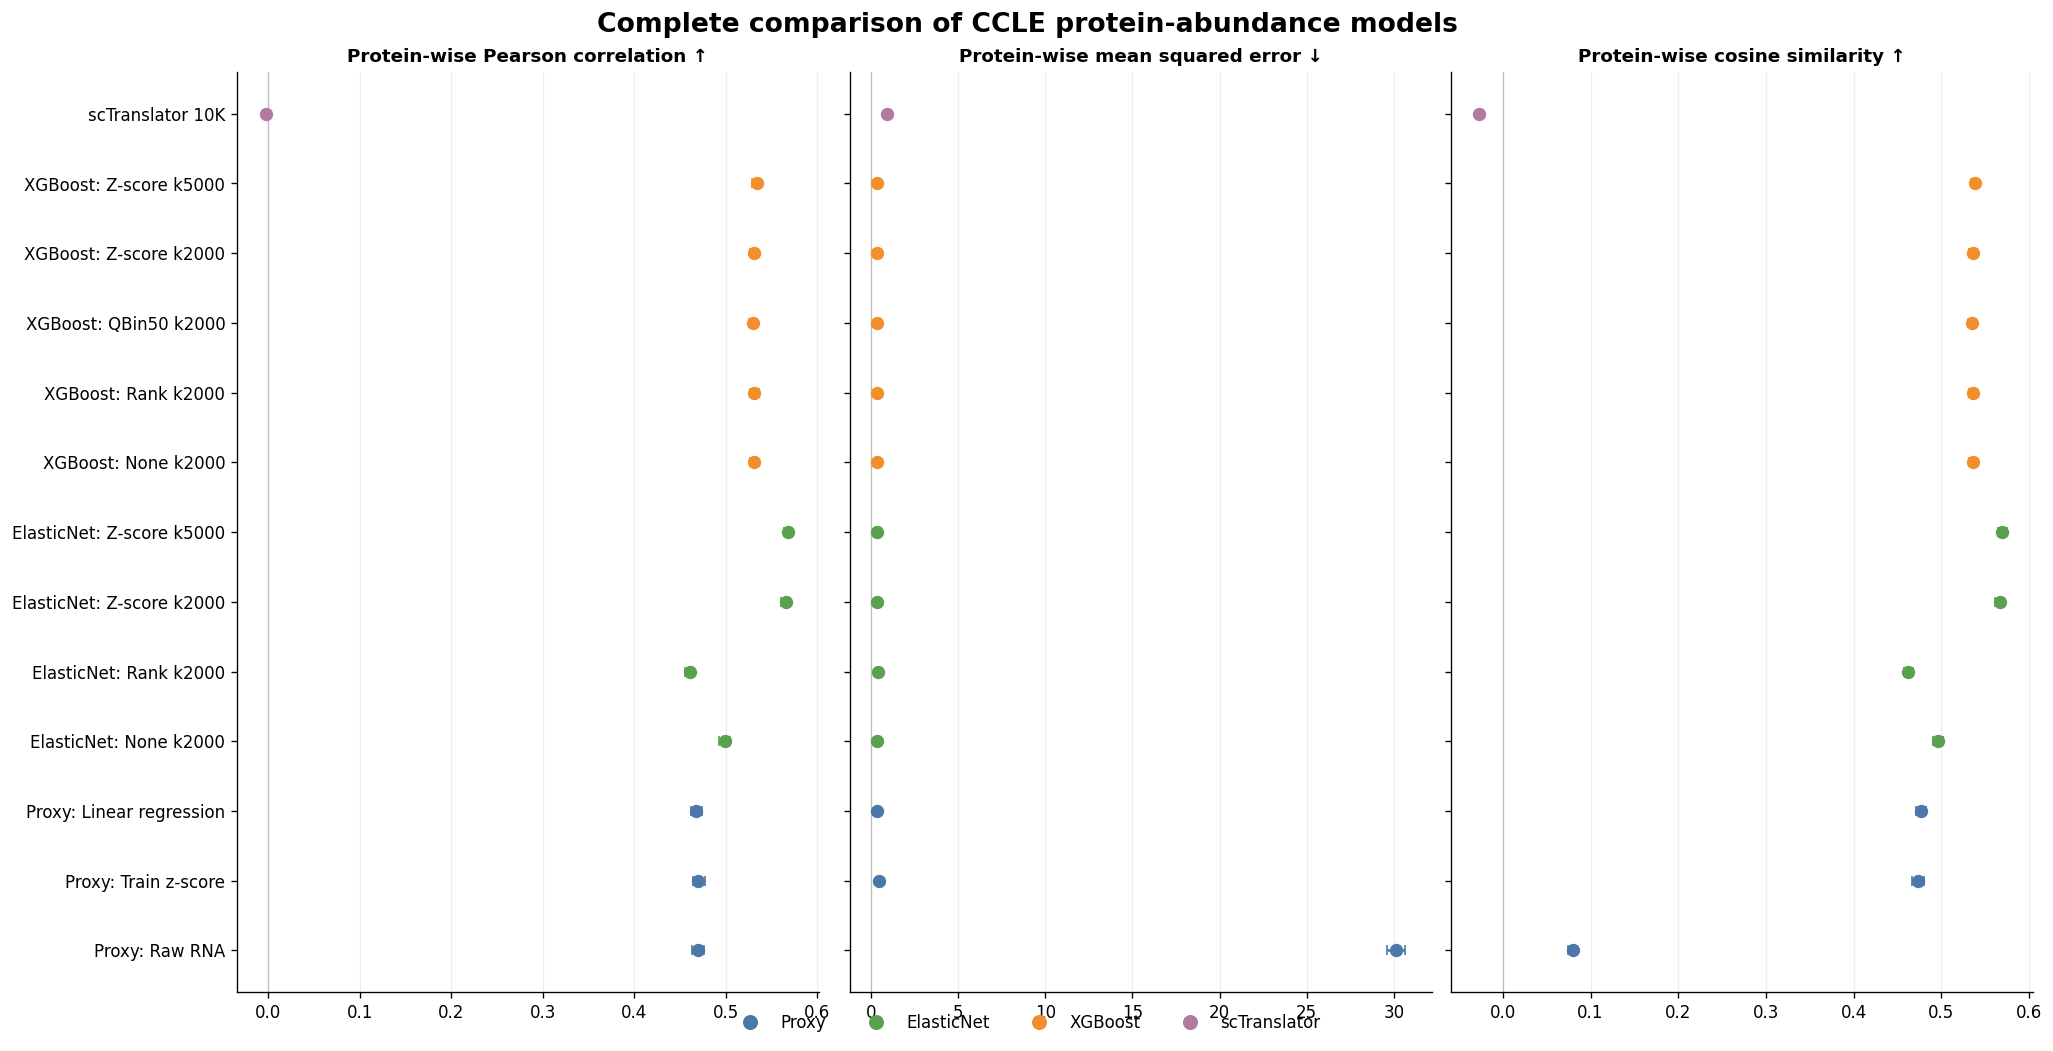

In [10]:
metric_specs = [
    ("pcc", "Protein-wise Pearson correlation", True),
    ("mse", "Protein-wise mean squared error", False),
    ("cosine", "Protein-wise cosine similarity", True),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 8.5), constrained_layout=True)
y_positions = np.arange(len(model_order))

for ax, (metric, title, higher) in zip(axes, metric_specs):
    for y, model in enumerate(model_order):
        group = all_results[all_results["model"].astype(str).eq(model)]
        values = pd.to_numeric(group[metric], errors="coerce").dropna()
        family_values = group["model_family"].dropna().astype(str)
        family = family_values.iloc[0] if len(family_values) else (
            "scTranslator" if "scTranslator" in model else "Proxy" if model.startswith("Proxy")
            else "ElasticNet" if model.startswith("ElasticNet") else "XGBoost"
        )
        if len(values):
            mean, lo, hi = mean_ci(values, seed=RANDOM_SEED + y)
        else:
            continue
        ax.errorbar(
            mean, y, xerr=[[max(mean - lo, 0)], [max(hi - mean, 0)]],
            fmt="o", markersize=7, capsize=3, linewidth=1.5,
            color=FAMILY_COLORS.get(family, "#777777"),
        )
    ax.set_title(title + (" ↑" if higher else " ↓"), fontweight="bold")
    ax.set_yticks(y_positions)
    ax.set_yticklabels(model_order if ax is axes[0] else [])
    ax.axvline(0, color="#777777", linewidth=0.8, alpha=0.4)
    ax.grid(axis="y", visible=False)

fig.suptitle("Complete comparison of CCLE protein-abundance models", fontsize=16, fontweight="bold")
legend_handles = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=color, markeredgecolor=color, label=family, markersize=8)
    for family, color in FAMILY_COLORS.items()
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
save_figure(fig, "figure1_all_models_mean_performance")
plt.show()


## 10. Figure 2 — matched-scope comparison (headline result)

Figure 1 and Section 7 are unrestricted: each model is averaged over whatever proteins it happens to
cover, and scTranslator is averaged over every sample in its prediction file. Those means are not
comparable to each other.

This section fixes the scope for every model:

- **proteins** — the proteins the other models were actually evaluated on (the intersection across the
  reference models, relaxed to their union only if the intersection is smaller than
  `MATCHED_SCOPE_MIN_PROTEINS`);
- **samples** — the recovered held-out test split, so scTranslator is scored only on the test cell lines
  and never on samples the other models never saw.

scTranslator is re-scored from the aligned prediction matrix inside that scope. If the aligned matrix is
unavailable, the sample restriction is skipped and the figure and manifest both say so explicitly.


In [11]:
# ------------------------------------------------------------------
# Build the matched evaluation scope and re-score scTranslator inside it.
# ------------------------------------------------------------------
SC_MODEL_NAME = "scTranslator 10K"
SC_MATCHED_NAME = "scTranslator 10K (matched)"


def _protein_key(value) -> str:
    """Case- and version-insensitive key used to match protein identifiers."""
    text = str(value).strip().upper()
    return re.sub(r"\.\d+$", "", text)


reference_models = [model for model in model_order if model != SC_MODEL_NAME]

reference_protein_keys = {}
for model in reference_models:
    group = all_results[all_results["model"].astype(str).eq(model)]
    keys = {_protein_key(p) for p in group.dropna(subset=["pcc"])["protein"].astype(str)}
    if keys:
        reference_protein_keys[model] = keys

if not reference_protein_keys:
    raise RuntimeError(
        "No reference model exposes per-protein metrics, so a matched-scope comparison cannot be built."
    )

intersection_keys = set.intersection(*reference_protein_keys.values())
union_keys = set.union(*reference_protein_keys.values())

# Proteins scTranslator can actually be scored on.
if SC_PRED_DF is not None:
    sc_available_keys = {_protein_key(c) for c in SC_PRED_DF.columns}
elif not sc_per_protein.empty:
    sc_available_keys = {_protein_key(p) for p in sc_per_protein["protein"].astype(str)}
else:
    sc_available_keys = set()

candidate_keys = intersection_keys & sc_available_keys if sc_available_keys else set(intersection_keys)
protein_rule = "intersection of all reference models"
if len(candidate_keys) < MATCHED_SCOPE_MIN_PROTEINS:
    fallback = (union_keys & sc_available_keys) if sc_available_keys else set(union_keys)
    if len(fallback) > len(candidate_keys):
        candidate_keys = fallback
        protein_rule = "union of reference models (the intersection was below MATCHED_SCOPE_MIN_PROTEINS)"

matched_protein_keys = sorted(candidate_keys)
if not matched_protein_keys:
    raise RuntimeError("The matched protein scope is empty; check protein naming across the artifacts.")

# ------------------------------------------------------------------
# Re-score scTranslator on the held-out test samples only.
# ------------------------------------------------------------------
sc_matched = pd.DataFrame()
sc_scope_rows = []
sc_matched_is_test_restricted = False
matched_samples = pd.Index([], dtype=object)


def score_sc_subset(sample_index: pd.Index, protein_keys) -> pd.DataFrame:
    """Protein-wise metrics for scTranslator on an explicit sample/protein subset."""
    key_to_column = {}
    for column in SC_PRED_DF.columns:
        key_to_column.setdefault(_protein_key(column), column)
    columns = [key_to_column[key] for key in protein_keys if key in key_to_column]
    if not columns or len(sample_index) == 0:
        return pd.DataFrame()
    true_block = SC_TRUE_DF.loc[sample_index, columns]
    pred_block = SC_PRED_DF.loc[sample_index, columns]
    rows = []
    for column in columns:
        rows.append({
            "protein": column,
            **metric_values(true_block[column].to_numpy(dtype=float),
                            pred_block[column].to_numpy(dtype=float)),
        })
    return pd.DataFrame(rows)


if SC_PRED_DF is not None:
    sc_samples = SC_PRED_DF.index
    overlap = pd.Index([s for s in sc_samples if s in set(test_samples.astype(str))])
    all_sc_keys = sorted({_protein_key(c) for c in SC_PRED_DF.columns})

    # Diagnostic ladder: how much of the difference is scope rather than model quality.
    scope_specs = [
        ("All samples x all scTranslator proteins", sc_samples, all_sc_keys),
        ("All samples x matched proteins", sc_samples, matched_protein_keys),
    ]
    if len(overlap):
        scope_specs.append(("Test samples x matched proteins", overlap, matched_protein_keys))

    for label, samples, keys in scope_specs:
        scored = score_sc_subset(samples, keys)
        if scored.empty:
            continue
        row = {"scope": label, "samples": int(len(samples)), "proteins": int(scored["protein"].nunique())}
        for metric in ["pcc", "mse", "cosine", "r2"]:
            values = pd.to_numeric(scored[metric], errors="coerce").dropna()
            row[f"mean_{metric}"] = float(values.mean()) if len(values) else np.nan
        sc_scope_rows.append(row)
        if label.startswith("Test samples"):
            sc_matched = scored
            matched_samples = overlap
            sc_matched_is_test_restricted = True

    if sc_matched.empty:
        # Sample labels could not be intersected with the recovered split.
        sc_matched = score_sc_subset(sc_samples, matched_protein_keys)
        matched_samples = sc_samples
        sc_matched_is_test_restricted = False

if sc_matched.empty and not sc_per_protein.empty:
    # No aligned matrix: fall back to restricting the supplied metric table by protein only.
    fallback_sc = sc_per_protein.copy()
    fallback_sc["_key"] = fallback_sc["protein"].astype(str).map(_protein_key)
    sc_matched = fallback_sc[fallback_sc["_key"].isin(set(matched_protein_keys))].drop(columns="_key")
    sc_matched_is_test_restricted = False

if sc_matched_is_test_restricted:
    sc_scope_note = (
        f"scTranslator re-scored on {len(matched_samples)} held-out test samples "
        f"and {sc_matched['protein'].nunique()} matched proteins"
    )
elif not sc_matched.empty:
    sc_scope_note = (
        "scTranslator restricted by protein only; the held-out sample restriction could not be applied "
        f"({SC_MATRIX_NOTE})"
    )
else:
    sc_scope_note = "no scTranslator metrics were available inside the matched scope"

# ------------------------------------------------------------------
# Assemble the matched per-protein table.
# ------------------------------------------------------------------
protein_key_series = all_results["protein"].astype(str).map(_protein_key)
reference_mask = (
    all_results["model"].astype(str).isin(reference_models)
    & protein_key_series.isin(set(matched_protein_keys))
)
matched_parts = [all_results.loc[reference_mask, model_metric_columns].copy()]

if not sc_matched.empty:
    sc_block = sc_matched.copy()
    sc_block["model"] = SC_MATCHED_NAME
    sc_block["model_family"] = "scTranslator"
    sc_block["normalization"] = "checkpoint 10K"
    sc_block["select_k"] = np.nan
    sc_block["scope"] = "protein-wise (matched)"
    sc_block["source"] = sc_scope_note
    for column in model_metric_columns:
        if column not in sc_block:
            sc_block[column] = np.nan
    matched_parts.append(sc_block[model_metric_columns])

matched_results = pd.concat(matched_parts, ignore_index=True, sort=False)
for metric in ["pcc", "mse", "cosine", "r2"]:
    matched_results[metric] = pd.to_numeric(matched_results[metric], errors="coerce")

matched_model_order = [
    model for model in reference_models
    if model in set(matched_results["model"].astype(str))
]
if SC_MATCHED_NAME in set(matched_results["model"].astype(str)):
    matched_model_order.append(SC_MATCHED_NAME)
matched_results["model"] = pd.Categorical(
    matched_results["model"].astype(str), categories=matched_model_order, ordered=True
)

print("Matched evaluation scope")
print("- Protein rule:       ", protein_rule)
print("- Matched proteins:   ", len(matched_protein_keys))
print("- Held-out test split:", len(test_samples), "samples |", split_source)
print("- scTranslator scope: ", sc_scope_note)
print("- Models compared:    ", len(matched_model_order))

if sc_scope_rows:
    sc_scope_table = pd.DataFrame(sc_scope_rows)
    print("\nEffect of evaluation scope on scTranslator alone")
    display(sc_scope_table.round(4))
    if SAVE_TABLES:
        sc_scope_table.to_csv(TABLE_DIR / "sctranslator_scope_effect.csv", index=False)
else:
    sc_scope_table = pd.DataFrame()
    print("\nNo scTranslator scope ladder could be computed (no aligned prediction matrix).")


Matched evaluation scope
- Protein rule:        intersection of all reference models
- Matched proteins:    4734
- Held-out test split: 74 samples | h5 test sample names: A2M_enet_8020_none_fast_k2000.h5
- scTranslator scope:  scTranslator re-scored on 74 held-out test samples and 4734 matched proteins
- Models compared:     13

Effect of evaluation scope on scTranslator alone


,scope,samples,proteins,mean_pcc,mean_mse,mean_cosine,mean_r2
0,All samples x all scTranslator proteins,369,5112,-0.0023,0.9029,-0.0267,-0.7674
1,All samples x matched proteins,369,4734,-0.0022,0.9103,-0.0263,-0.7616
2,Test samples x matched proteins,74,4734,-0.0113,0.8765,-0.0239,-0.8554


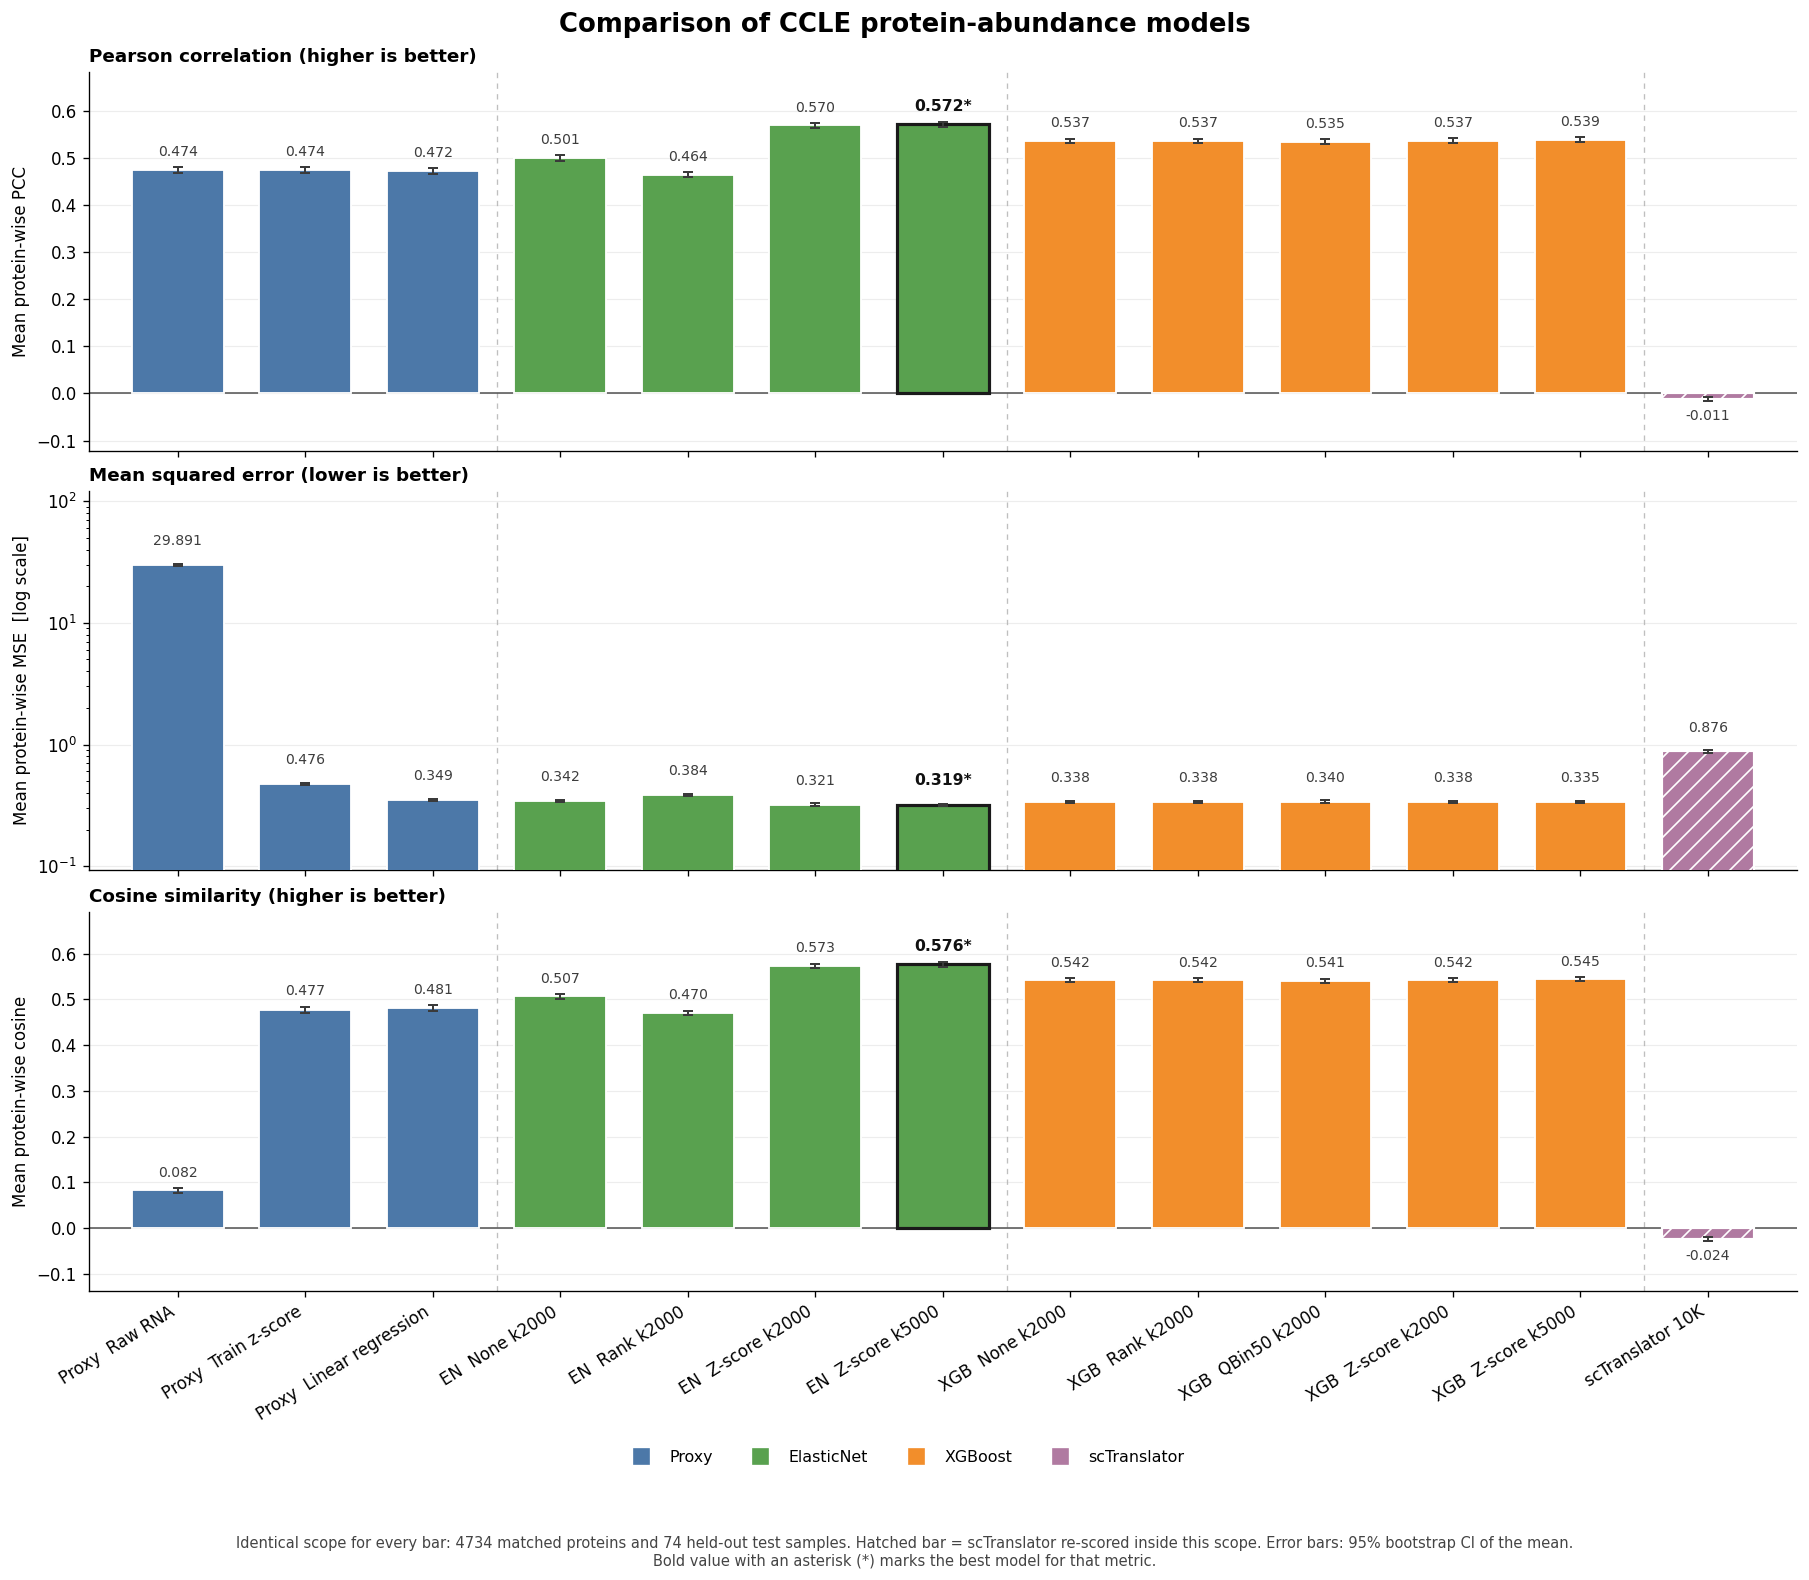

**Matched-scope summary** — 4734 proteins, 74 held-out test samples, 13 models. scTranslator re-scored on 74 held-out test samples and 4734 matched proteins. Bold cells marked with an asterisk (*) are the best model for that metric.

Model,Family,Proteins,PCC,PCC 95% CI,MSE,MSE 95% CI,Cosine,Cosine 95% CI,R2,R2 95% CI
Proxy: Raw RNA,Proxy,4734,0.4741 ± 0.2328,"[0.468, 0.481]",29.8913 ± 20.2083,"[29.261, 30.495]",0.0825 ± 0.1722,"[0.077, 0.088]",-97.6185 ± 120.3324,"[-100.899, -94.217]"
Proxy: Train z-score,Proxy,4734,0.4741 ± 0.2328,"[0.468, 0.481]",0.4757 ± 0.3496,"[0.466, 0.485]",0.4772 ± 0.2305,"[0.471, 0.484]",-0.1020 ± 0.5154,"[-0.117, -0.087]"
Proxy: Linear regression,Proxy,4734,0.4719 ± 0.2372,"[0.465, 0.479]",0.3491 ± 0.2515,"[0.342, 0.356]",0.4808 ± 0.2260,"[0.474, 0.487]",0.2507 ± 0.2222 *,"[0.244, 0.257]"
ElasticNet: None k2000,ElasticNet,4734,0.5006 ± 0.2009,"[0.494, 0.506]",0.3422 ± 0.2309,"[0.336, 0.349]",0.5065 ± 0.1951,"[0.500, 0.512]",NA,nan
ElasticNet: Rank k2000,ElasticNet,4734,0.4644 ± 0.1830,"[0.459, 0.470]",0.3836 ± 0.2825,"[0.375, 0.392]",0.4702 ± 0.1775,"[0.465, 0.475]",NA,nan
ElasticNet: Z-score k2000,ElasticNet,4734,0.5696 ± 0.1753,"[0.565, 0.575]",0.3212 ± 0.2395,"[0.315, 0.328]",0.5735 ± 0.1711,"[0.569, 0.578]",NA,nan
ElasticNet: Z-score k5000,ElasticNet,4734,0.5715 ± 0.1725 *,"[0.567, 0.576]",0.3194 ± 0.2423 *,"[0.313, 0.326]",0.5762 ± 0.1675 *,"[0.571, 0.581]",NA,nan
XGBoost: None k2000,XGBoost,4734,0.5366 ± 0.1684,"[0.532, 0.541]",0.3382 ± 0.2466,"[0.331, 0.345]",0.5420 ± 0.1636,"[0.537, 0.547]",NA,nan
XGBoost: Rank k2000,XGBoost,4734,0.5366 ± 0.1684,"[0.532, 0.541]",0.3382 ± 0.2466,"[0.331, 0.345]",0.5420 ± 0.1636,"[0.537, 0.547]",NA,nan
XGBoost: QBin50 k2000,XGBoost,4734,0.5350 ± 0.1680,"[0.530, 0.540]",0.3398 ± 0.2479,"[0.333, 0.347]",0.5405 ± 0.1631,"[0.536, 0.545]",NA,nan


Matched-scope rankings


,metric,rank,model,model_family,n,mean,std,difference_from_best
0,pcc,1,ElasticNet: Z-score k5000,ElasticNet,4734,0.5715,0.1725,0.0000
1,pcc,2,ElasticNet: Z-score k2000,ElasticNet,4734,0.5696,0.1753,-0.0020
2,pcc,3,XGBoost: Z-score k5000,XGBoost,4734,0.5391,0.1702,-0.0324
3,pcc,4,XGBoost: None k2000,XGBoost,4734,0.5366,0.1684,-0.0350
4,pcc,5,XGBoost: Rank k2000,XGBoost,4734,0.5366,0.1684,-0.0350
5,pcc,6,XGBoost: Z-score k2000,XGBoost,4734,0.5366,0.1684,-0.0350
6,pcc,7,XGBoost: QBin50 k2000,XGBoost,4734,0.5350,0.1680,-0.0365
7,pcc,8,ElasticNet: None k2000,ElasticNet,4734,0.5006,0.2009,-0.0709
8,pcc,9,Proxy: Raw RNA,Proxy,4734,0.4741,0.2328,-0.0974
9,pcc,10,Proxy: Train z-score,Proxy,4734,0.4741,0.2328,-0.0974


In [18]:
# ------------------------------------------------------------------
# Figure 2 - matched-scope mean performance bar plot, and its summary table.
# ------------------------------------------------------------------
matched_summary_long = summarize_results(matched_results)
if matched_summary_long.empty:
    raise RuntimeError("The matched-scope table produced no numeric metrics.")
matched_summary_long["model"] = pd.Categorical(
    matched_summary_long["model"], categories=matched_model_order, ordered=True
)
matched_summary_long = matched_summary_long.sort_values(["metric", "model"]).reset_index(drop=True)

# Bootstrap intervals, computed once and reused by the figure and the table.
ci_records = []
for position, model in enumerate(matched_model_order):
    group = matched_results[matched_results["model"].astype(str).eq(model)]
    for metric in ["pcc", "mse", "cosine", "r2"]:
        values = pd.to_numeric(group[metric], errors="coerce").dropna()
        if values.empty:
            continue
        mean, low, high = mean_ci(values, seed=RANDOM_SEED + position)
        ci_records.append({
            "model": model, "metric": metric, "n": int(len(values)),
            "mean": mean, "ci_low": low, "ci_high": high,
        })
matched_ci = pd.DataFrame(ci_records)
ci_lookup = matched_ci.set_index(["model", "metric"]) if not matched_ci.empty else pd.DataFrame()

bar_metric_specs = [
    ("pcc", "Pearson correlation", "Mean protein-wise PCC", True),
    ("mse", "Mean squared error", "Mean protein-wise MSE", False),
    ("cosine", "Cosine similarity", "Mean protein-wise cosine", True),
]
if MATCHED_SCOPE_INCLUDE_R2:
    bar_metric_specs.append(("r2", "Coefficient of determination", "Mean protein-wise $R^2$", True))


def _short_label(name: str) -> str:
    return (
        str(name)
        .replace("ElasticNet: ", "EN  ")
        .replace("XGBoost: ", "XGB  ")
        .replace("Proxy: ", "Proxy  ")
        .replace("scTranslator 10K (matched)", "scTranslator 10K")
    )


family_of = {}
for model_name, group in matched_results.groupby("model", observed=True):
    families = group["model_family"].dropna().astype(str)
    family_of[str(model_name)] = families.iloc[0] if len(families) else "Unknown"

positions = np.arange(len(matched_model_order))
labels = [_short_label(model) for model in matched_model_order]
bar_families = [family_of.get(model, "Unknown") for model in matched_model_order]
bar_colors = [FAMILY_COLORS.get(family, "#8C8C8C") for family in bar_families]
family_boundaries = [
    index - 0.5 for index in range(1, len(bar_families))
    if bar_families[index] != bar_families[index - 1]
]

n_panels = len(bar_metric_specs)
fig, axes = plt.subplots(
    n_panels, 1,
    figsize=(max(11.0, 0.92 * len(matched_model_order) + 3.0), 3.55 * n_panels + 1.2),
    sharex=True, constrained_layout=True,
)
axes = np.atleast_1d(axes)

for ax, (metric, panel_title, axis_label, higher) in zip(axes, bar_metric_specs):
    means, lows, highs = [], [], []
    for model in matched_model_order:
        if not ci_lookup.empty and (model, metric) in ci_lookup.index:
            row = ci_lookup.loc[(model, metric)]
            means.append(float(row["mean"]))
            lows.append(float(row["ci_low"]))
            highs.append(float(row["ci_high"]))
        else:
            means.append(np.nan)
            lows.append(np.nan)
            highs.append(np.nan)

    means = np.asarray(means, dtype=float)
    lower_error = np.where(np.isfinite(means) & np.isfinite(lows), means - np.asarray(lows, dtype=float), 0.0)
    upper_error = np.where(np.isfinite(means) & np.isfinite(highs), np.asarray(highs, dtype=float) - means, 0.0)
    errors = np.vstack([np.clip(lower_error, 0, None), np.clip(upper_error, 0, None)])

    heights = np.where(np.isfinite(means), means, 0.0)

    # One badly-scaled model (raw RNA MSE, typically) can flatten every other
    # bar. When all values are positive and the range is extreme, use a log axis
    # so the informative bars stay readable.
    finite_means = means[np.isfinite(means)]
    use_log = (
        BAR_LOG_SCALE_RATIO > 0
        and len(finite_means) > 2
        and bool(np.all(finite_means > 0))
        and float(finite_means.max()) > BAR_LOG_SCALE_RATIO * float(np.median(finite_means))
    )

    bars = ax.bar(
        positions, heights, width=0.72, color=bar_colors,
        edgecolor="white", linewidth=1.1, zorder=3,
    )
    ax.errorbar(
        positions, heights, yerr=errors, fmt="none",
        ecolor="#3A3A3A", elinewidth=1.2, capsize=3.2, capthick=1.2, zorder=4,
    )

    # Mark the re-scored scTranslator bar so the matched scope is visible in the figure.
    for bar, model in zip(bars, matched_model_order):
        if model == SC_MATCHED_NAME:
            bar.set_hatch("//")
            bar.set_edgecolor("#FFFFFF")
            bar.set_linewidth(1.3)

    # Axis limits leave room for the interval whiskers and the printed means.
    if use_log:
        ax.set_yscale("log")
        upper = float(np.nanmax(np.where(np.isfinite(highs), highs, means)))
        lower = float(np.nanmin(np.where(np.isfinite(lows), lows, means)))
        ax.set_ylim(max(lower * 0.30, 1e-8), upper * 4.0)
    else:
        extremes = np.concatenate([
            heights - errors[0], heights + errors[1], np.asarray([0.0]),
        ])
        extremes = extremes[np.isfinite(extremes)]
        if len(extremes):
            span = float(extremes.max() - extremes.min())
            pad = 0.18 * span if span > 0 else 0.1
            ax.set_ylim(float(extremes.min()) - pad, float(extremes.max()) + pad)

    # Best model for this metric: bold label carrying an asterisk.
    finite_mask = np.isfinite(means)
    if finite_mask.any():
        scored = np.where(finite_mask, means, -np.inf if higher else np.inf)
        best_index = int(np.argmax(scored)) if higher else int(np.argmin(scored))
    else:
        best_index = -1

    offset = 0.022 * (ax.get_ylim()[1] - ax.get_ylim()[0])
    for index, (position, mean_value, low_value, high_value) in enumerate(zip(positions, means, lows, highs)):
        if not np.isfinite(mean_value):
            ax.text(position, ax.get_ylim()[0], "NA", ha="center", va="bottom", fontsize=8, color="#777777")
            continue
        is_best = index == best_index
        text = f"{mean_value:.3f}*" if is_best else f"{mean_value:.3f}"
        weight = "bold" if is_best else "normal"
        size = 9.4 if is_best else 8.4
        color = "#111111" if is_best else "#3D3D3D"
        if use_log:
            anchor = high_value if np.isfinite(high_value) else mean_value
            ax.text(position, anchor * 1.35, text, ha="center", va="bottom",
                    fontsize=size, fontweight=weight, color=color)
        elif mean_value >= 0:
            anchor = high_value if np.isfinite(high_value) else mean_value
            ax.text(position, anchor + offset, text, ha="center", va="bottom",
                    fontsize=size, fontweight=weight, color=color)
        else:
            anchor = low_value if np.isfinite(low_value) else mean_value
            ax.text(position, anchor - offset, text, ha="center", va="top",
                    fontsize=size, fontweight=weight, color=color)

    if best_index >= 0:
        bars[best_index].set_edgecolor("#1A1A1A")
        bars[best_index].set_linewidth(1.9)

    # Thin separators between model families keep a 14-bar panel readable.
    for boundary in family_boundaries:
        ax.axvline(boundary, color="#BFBFBF", linewidth=0.8, linestyle=(0, (4, 4)), zorder=1)

    ax.set_title(f"{panel_title} " + ("(higher is better)" if higher else "(lower is better)"),
                 fontweight="bold", loc="left")
    ax.set_ylabel(axis_label + ("  [log scale]" if use_log else ""))
    if not use_log:
        ax.axhline(0, color="#4D4D4D", linewidth=0.9, zorder=2)
    ax.set_xlim(-0.7, len(matched_model_order) - 0.3)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.22, zorder=0)

axes[-1].set_xticks(positions)
axes[-1].set_xticklabels(labels, rotation=32, ha="right")

scope_line = (
    f"Identical scope for every bar: {len(matched_protein_keys)} matched proteins"
    + (f" and {len(matched_samples)} held-out test samples" if sc_matched_is_test_restricted else "")
    + ". Hatched bar = scTranslator re-scored inside this scope. Error bars: 95% bootstrap CI of the mean."
    + "\nBold value with an asterisk (*) marks the best model for that metric."
)
fig.suptitle("Comparison of CCLE protein-abundance models",
             fontsize=15.5, fontweight="bold")

legend_handles = [
    Line2D([0], [0], marker="s", color="none", markerfacecolor=color, markeredgecolor=color,
           label=family, markersize=9)
    for family, color in FAMILY_COLORS.items()
    if family in set(bar_families)
]
fig.legend(handles=legend_handles, loc="lower center", ncol=max(1, len(legend_handles)),
           bbox_to_anchor=(0.5, -0.035), fontsize=9.5)
fig.text(0.5, -0.075, scope_line, ha="center", va="top", fontsize=8.8, color="#444444")

save_figure(fig, "figure2_matched_scope_mean_performance")
plt.show()

# ------------------------------------------------------------------
# Summary table for the matched scope.
# ------------------------------------------------------------------
matched_wide = matched_summary_long.pivot(
    index=["model", "model_family"], columns="metric", values=["n", "mean", "std"]
)
matched_wide.columns = [f"{stat}_{metric}" for stat, metric in matched_wide.columns]
matched_wide = matched_wide.reset_index()

ci_text = {}
if not matched_ci.empty:
    for _, row in matched_ci.iterrows():
        ci_text[(row["model"], row["metric"])] = f"[{row['ci_low']:.3f}, {row['ci_high']:.3f}]"

table_rows = []
best_by_metric = {}
for metric, higher in [("pcc", True), ("mse", False), ("cosine", True), ("r2", True)]:
    sub = matched_summary_long[matched_summary_long["metric"].eq(metric)].dropna(subset=["mean"])
    if not sub.empty:
        best_by_metric[metric] = str(sub.sort_values("mean", ascending=not higher).iloc[0]["model"])

for model in matched_model_order:
    record = {"Model": model, "Family": family_of.get(model, "Unknown")}
    proteins = matched_results[matched_results["model"].astype(str).eq(model)]["protein"].nunique()
    record["Proteins"] = int(proteins)
    for metric, label in [("pcc", "PCC"), ("mse", "MSE"), ("cosine", "Cosine"), ("r2", "R2")]:
        row = matched_summary_long[
            matched_summary_long["model"].astype(str).eq(model)
            & matched_summary_long["metric"].eq(metric)
        ]
        if row.empty or pd.isna(row.iloc[0]["mean"]):
            record[label] = "NA"
            continue
        mean_value = float(row.iloc[0]["mean"])
        std_value = float(row.iloc[0]["std"])
        marker = " *" if best_by_metric.get(metric) == model else ""
        record[label] = f"{mean_value:.4f} ± {std_value:.4f}{marker}"
        record[f"{label} 95% CI"] = ci_text.get((model, metric), "")
    table_rows.append(record)

matched_paper_table = pd.DataFrame(table_rows)
ordered_columns = ["Model", "Family", "Proteins"]
for label in ["PCC", "MSE", "Cosine", "R2"]:
    for column in [label, f"{label} 95% CI"]:
        if column in matched_paper_table:
            ordered_columns.append(column)
matched_paper_table = matched_paper_table[ordered_columns]

# Rankings inside the matched scope.
matched_rank_rows = []
for metric, higher in [("pcc", True), ("mse", False), ("cosine", True)]:
    sub = matched_summary_long[matched_summary_long["metric"].eq(metric)].dropna(subset=["mean"]).copy()
    if sub.empty:
        continue
    sub = sub.sort_values("mean", ascending=not higher).reset_index(drop=True)
    sub["rank"] = np.arange(1, len(sub) + 1)
    sub["difference_from_best"] = sub["mean"] - sub["mean"].iloc[0]
    matched_rank_rows.append(sub[["metric", "rank", "model", "model_family", "n", "mean", "std", "difference_from_best"]])
matched_rankings = pd.concat(matched_rank_rows, ignore_index=True) if matched_rank_rows else pd.DataFrame()

display(Markdown(
    f"**Matched-scope summary** \u2014 {len(matched_protein_keys)} proteins, "
    + (f"{len(matched_samples)} held-out test samples, " if sc_matched_is_test_restricted else "")
    + f"{len(matched_model_order)} models. {sc_scope_note}. "
    + "Bold cells marked with an asterisk (*) are the best model for that metric."
))


def highlight_best_cells(frame: pd.DataFrame) -> pd.DataFrame:
    """Bold the winning cell of each metric column."""
    styles = pd.DataFrame("", index=frame.index, columns=frame.columns)
    for metric, label in [("pcc", "PCC"), ("mse", "MSE"), ("cosine", "Cosine"), ("r2", "R2")]:
        best_model = best_by_metric.get(metric)
        if best_model is None or label not in frame.columns:
            continue
        mask = frame["Model"].astype(str).eq(best_model)
        for column in [label, f"{label} 95% CI"]:
            if column in frame.columns:
                styles.loc[mask, column] = "font-weight: 700; color: #111111;"
    return styles


try:
    display(matched_paper_table.style.apply(highlight_best_cells, axis=None).hide(axis="index"))
except Exception:
    display(matched_paper_table)

print("Matched-scope rankings")
display(matched_rankings.round(4))

if SAVE_TABLES:
    matched_results.to_csv(TABLE_DIR / "matched_scope_per_protein_metrics.csv", index=False)
    matched_summary_long.to_csv(TABLE_DIR / "matched_scope_summary_long.csv", index=False)
    matched_wide.to_csv(TABLE_DIR / "matched_scope_summary_wide.csv", index=False)
    matched_paper_table.to_csv(TABLE_DIR / "matched_scope_paper_table.csv", index=False)
    matched_rankings.to_csv(TABLE_DIR / "matched_scope_rankings.csv", index=False)


## 11. Figure 3 — PCC–MSE Pareto view

Models toward the lower-right combine stronger correlation with lower error. Marker area represents mean cosine similarity. Models without both protein-wise PCC and protein-wise MSE are not placed in this plot.


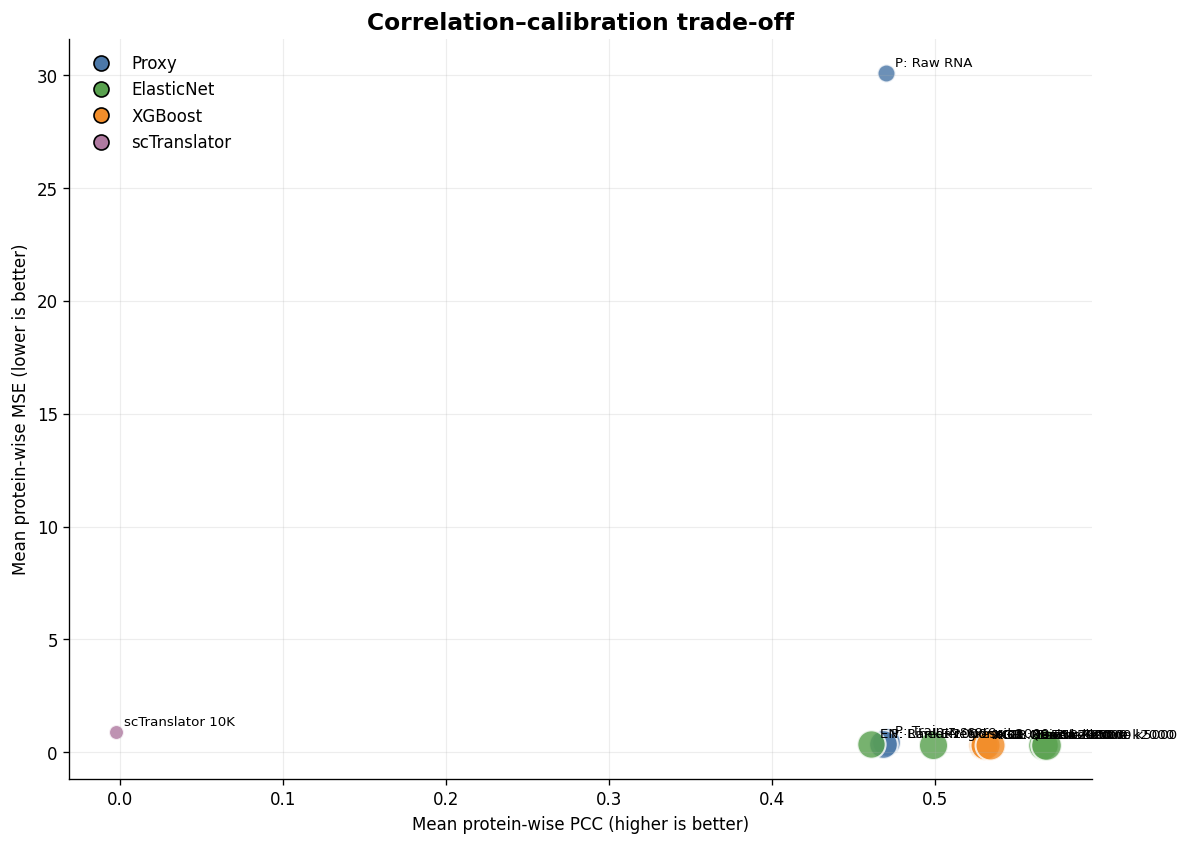

In [13]:
mean_matrix = summary_long.pivot(index="model", columns="metric", values="mean").reindex(model_order)

pareto = mean_matrix.dropna(subset=["pcc", "mse"]).copy()
family_lookup = all_results.drop_duplicates("model").set_index("model")["model_family"].astype(str).to_dict()

fig, ax = plt.subplots(figsize=(11, 8))
for model, row in pareto.iterrows():
    family = family_lookup.get(str(model), "scTranslator" if "scTranslator" in str(model) else "Unknown")
    cosine = row.get("cosine", np.nan)
    size = 80 + 450 * max(float(cosine), 0.0) if pd.notna(cosine) else 90
    ax.scatter(row["pcc"], row["mse"], s=size, color=FAMILY_COLORS.get(family, "#777777"), alpha=0.82, edgecolor="white", linewidth=1.2)
    ax.annotate(str(model).replace("ElasticNet: ", "EN: ").replace("XGBoost: ", "XGB: ").replace("Proxy: ", "P: "),
                (row["pcc"], row["mse"]), xytext=(5, 4), textcoords="offset points", fontsize=8)

ax.set_xlabel("Mean protein-wise PCC (higher is better)")
ax.set_ylabel("Mean protein-wise MSE (lower is better)")
ax.set_title("Correlation–calibration trade-off", fontsize=14, fontweight="bold")
legend_handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=color, label=family, markersize=9) for family, color in FAMILY_COLORS.items()]
ax.legend(handles=legend_handles, loc="best")
save_figure(fig, "figure3_pcc_mse_pareto")
plt.show()


## 12. Figure 4 — effect of normalization and feature-set size

The same y-axis metric is compared across transformations. The $k=5{,}000$ points correspond only to the larger z-score runs.


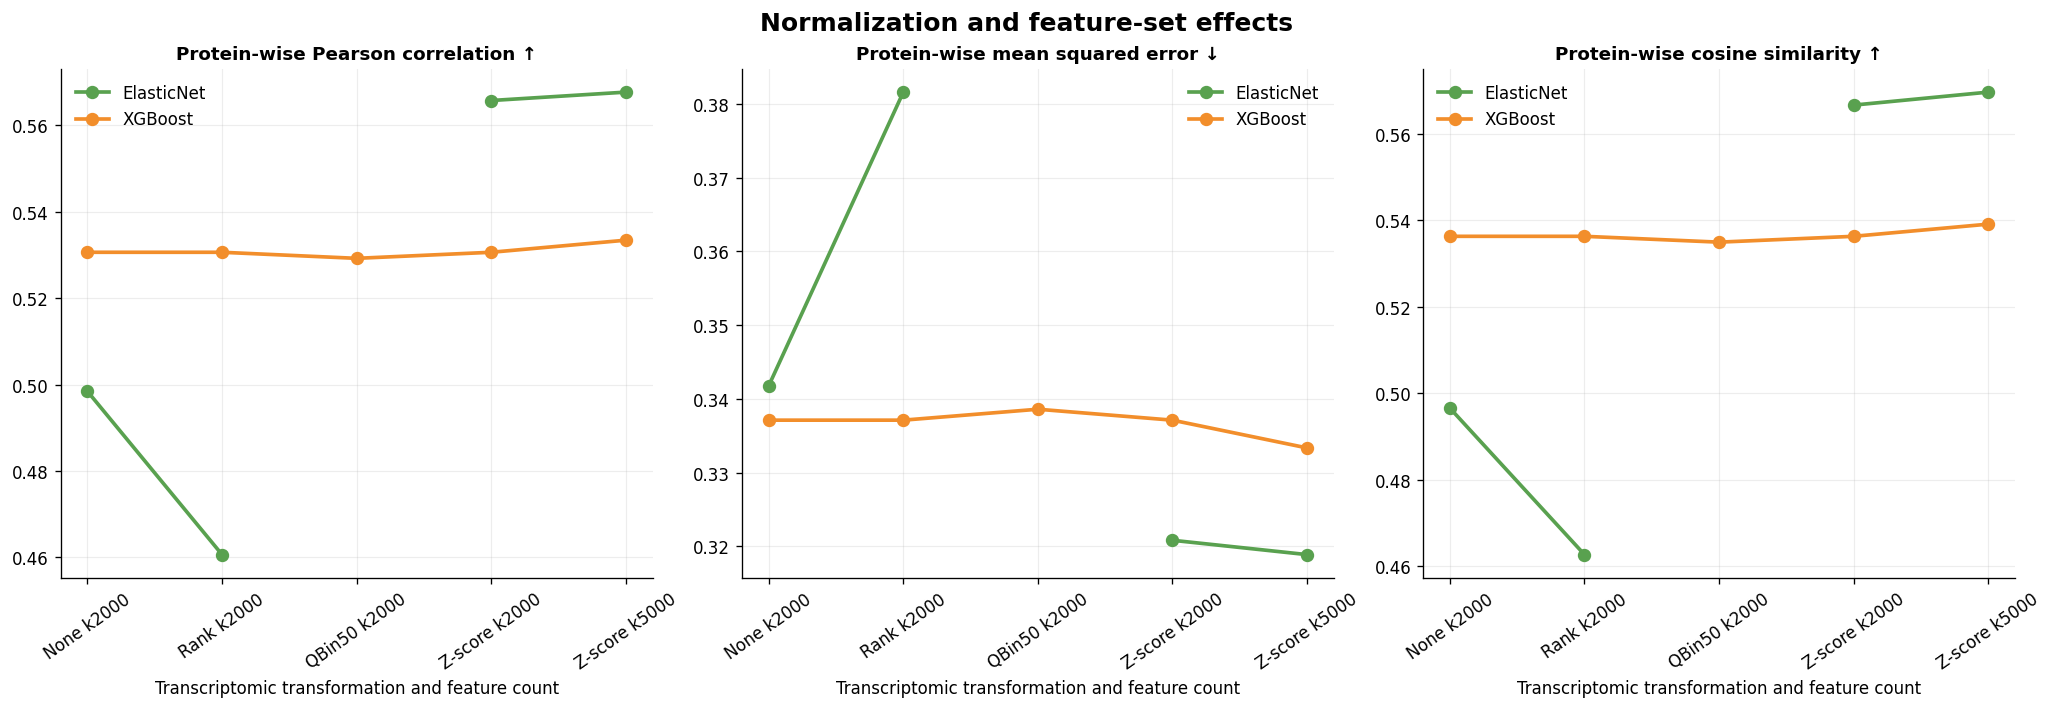

In [14]:
transform_order = ["None k2000", "Rank k2000", "QBin50 k2000", "Z-score k2000", "Z-score k5000"]
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8), constrained_layout=True)

for ax, (metric, title, higher) in zip(axes, metric_specs):
    for family in ["ElasticNet", "XGBoost"]:
        values = []
        for transform in transform_order:
            model = f"{family}: {transform}"
            row = summary_long[(summary_long["model"].astype(str).eq(model)) & summary_long["metric"].eq(metric)]
            values.append(float(row.iloc[0]["mean"]) if len(row) else np.nan)
        ax.plot(transform_order, values, marker="o", linewidth=2.2, markersize=7,
                color=FAMILY_COLORS[family], label=family)
    ax.set_title(title + (" ↑" if higher else " ↓"), fontweight="bold")
    ax.tick_params(axis="x", rotation=35)
    ax.set_xlabel("Transcriptomic transformation and feature count")
    ax.legend()

fig.suptitle("Normalization and feature-set effects", fontsize=15, fontweight="bold")
save_figure(fig, "figure4_normalization_and_k_effects")
plt.show()


## 13. Figure 5 — direct comparison of the three proxy formulations


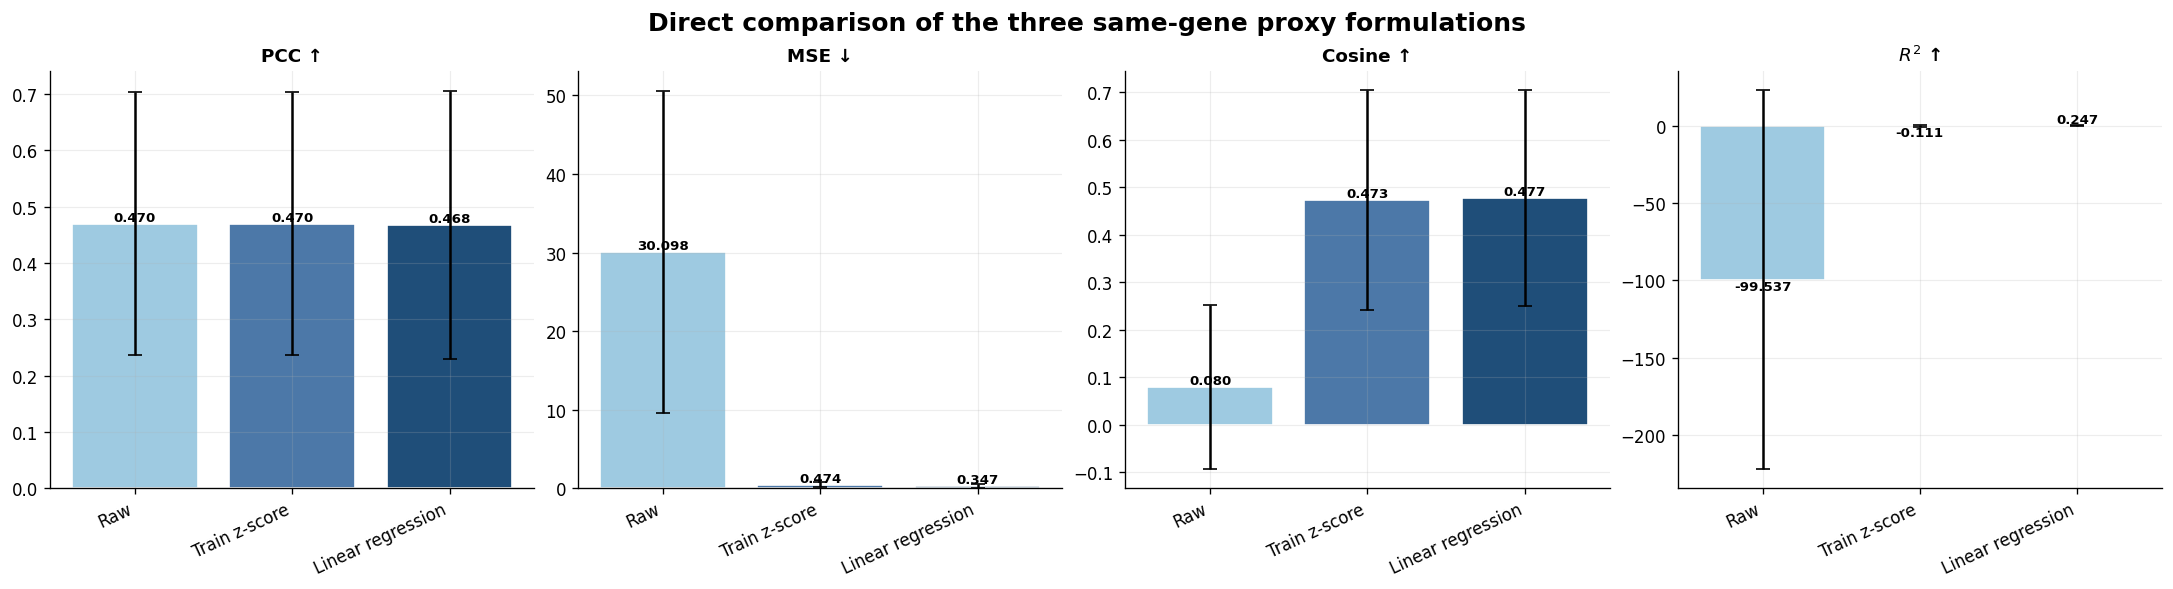

In [15]:
proxy_models = ["Proxy: Raw RNA", "Proxy: Train z-score", "Proxy: Linear regression"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8), constrained_layout=True)
proxy_specs_plot = [
    ("pcc", "PCC ↑"),
    ("mse", "MSE ↓"),
    ("cosine", "Cosine ↑"),
    ("r2", "$R^2$ ↑"),
]
proxy_palette = ["#9ECAE1", "#4C78A8", "#1F4E79"]

for ax, (metric, title) in zip(axes, proxy_specs_plot):
    means = []
    errors = []
    for model in proxy_models:
        row = summary_long[(summary_long["model"].astype(str).eq(model)) & summary_long["metric"].eq(metric)]
        means.append(float(row.iloc[0]["mean"]) if len(row) else np.nan)
        errors.append(float(row.iloc[0]["std"]) if len(row) and pd.notna(row.iloc[0]["std"]) else 0.0)
    x = np.arange(len(proxy_models))
    ax.bar(x, means, yerr=errors, capsize=4, color=proxy_palette, edgecolor="white")
    ax.set_xticks(x)
    ax.set_xticklabels(["Raw", "Train z-score", "Linear regression"], rotation=25, ha="right")
    ax.set_title(title, fontweight="bold")
    for xpos, value in zip(x, means):
        if pd.notna(value):
            ax.text(xpos, value, f"{value:.3f}", ha="center", va="bottom" if value >= 0 else "top", fontsize=8, fontweight="bold")

fig.suptitle("Direct comparison of the three same-gene proxy formulations", fontsize=15, fontweight="bold")
save_figure(fig, "figure5_proxy_formulations")
plt.show()


## 14. scTranslator 10K sample-wise reference

Sample-wise metrics are kept separate from protein-wise model summaries. This section is generated only when `sc_predictions_10K.npz` contains enough information to calculate them.


,model,metric,n,mean ± SD,source
4,scTranslator 10K,pcc,369,-0.0012 ± 0.0402,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
5,scTranslator 10K,mse,369,0.9029 ± 0.3238,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
6,scTranslator 10K,cosine,369,-0.0182 ± 0.0875,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...
7,scTranslator 10K,r2,369,-0.5297 ± 0.2142,C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-re...


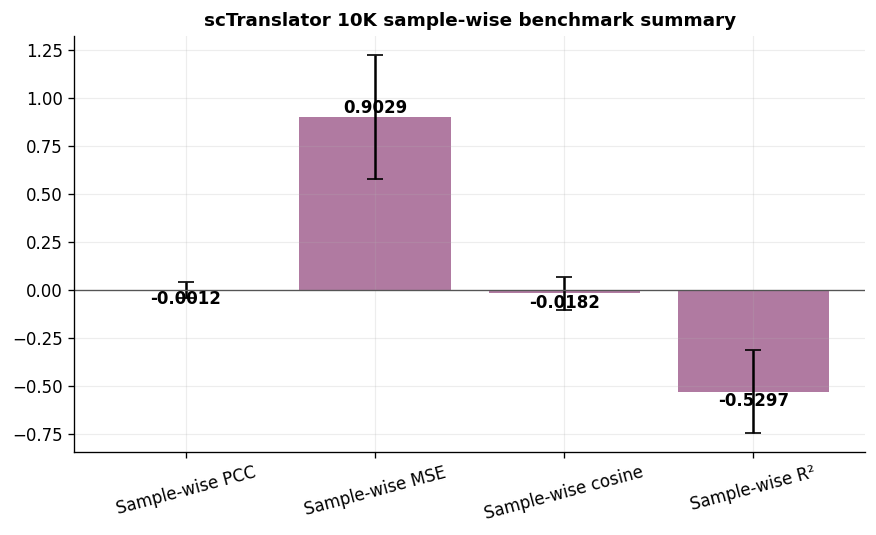

In [16]:
if sc_aggregate_summary.empty or not (sc_aggregate_summary["scope"] == "sample-wise").any():
    display(Markdown("**No sample-wise scTranslator 10K metrics were available from the supplied files.**"))
else:
    sc_sample_summary = sc_aggregate_summary.query("scope == 'sample-wise'").copy()
    sc_sample_summary["mean ± SD"] = sc_sample_summary.apply(
        lambda r: f"{r['mean']:.4f} ± {r['std']:.4f}", axis=1
    )
    display(sc_sample_summary[["model", "metric", "n", "mean ± SD", "source"]])

    metric_order = [m for m in ["pcc", "mse", "cosine", "r2"] if m in set(sc_sample_summary["metric"])]
    plot_sc = sc_sample_summary.set_index("metric").reindex(metric_order).reset_index()
    fig, ax = plt.subplots(figsize=(8.5, 4.5))
    x = np.arange(len(plot_sc))
    ax.bar(x, plot_sc["mean"], yerr=plot_sc["std"].fillna(0), capsize=5, color=FAMILY_COLORS["scTranslator"])
    label_map = {"pcc": "Sample-wise PCC", "mse": "Sample-wise MSE", "cosine": "Sample-wise cosine", "r2": "Sample-wise R²"}
    ax.set_xticks(x)
    ax.set_xticklabels([label_map[m] for m in metric_order], rotation=15)
    ax.set_title("scTranslator 10K sample-wise benchmark summary", fontweight="bold")
    ax.axhline(0, color="#555555", linewidth=0.8)
    for xpos, value in zip(x, plot_sc["mean"]):
        ax.text(xpos, value, f"{value:.4f}", ha="center", va="bottom" if value >= 0 else "top", fontweight="bold")
    save_figure(fig, "figure6_sctranslator_sample_wise_summary")
    plt.show()


## 15. Export manifest


In [17]:
manifest = {
    "project_root": str(ROOT),
    "output_directory": str(OUTPUT_DIR),
    "transcriptomics_path": str(X_PATH),
    "proteomics_path": str(Y_PATH),
    "test_split_hash": chosen_hash,
    "test_split_source": split_source,
    "exact_saved_split": bool(exact_saved_split),
    "train_samples": int(len(train_samples)),
    "test_samples": int(len(test_samples)),
    "models": model_order,
    "sctranslator_per_protein_table": None if sc_path is None else str(sc_path),
    "sctranslator_predictions_npz": None if sc_npz_path is None else str(sc_npz_path),
    "sctranslator_notes": sc_notes,
    "matched_scope_protein_rule": protein_rule,
    "matched_scope_proteins": int(len(matched_protein_keys)),
    "matched_scope_samples": int(len(matched_samples)),
    "matched_scope_sctranslator_restricted_to_test_split": bool(sc_matched_is_test_restricted),
    "matched_scope_note": sc_scope_note,
}

with open(OUTPUT_DIR / "comparison_manifest.json", "w", encoding="utf-8") as handle:
    json.dump(manifest, handle, indent=2)

print("Saved outputs")
print("- Figures:", FIGURE_DIR)
print("- Tables: ", TABLE_DIR)
print("- Manifest:", OUTPUT_DIR / "comparison_manifest.json")
print("\nFigure files:")
for path in sorted(FIGURE_DIR.glob("*.png")):
    print(" ", path.name)


Saved outputs
- Figures: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\complete_comparison_outputs\figures
- Tables:  C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\complete_comparison_outputs\tables
- Manifest: C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04.5 ccle comparison\complete_comparison_outputs\comparison_manifest.json

Figure files:
  all_models_protein_metrics_barplot_grid.png
  figure1_all_models_mean_performance.png
  figure2_matched_scope_mean_performance.png
  figure2_relative_performance_heatmap.png
  figure3_pcc_mse_pareto.png
  figure4_normalization_and_k_effects.png
  figure4_per_protein_winners.png
  figure4_threshold_coverage.png
  figure5_normalization_and_k_effects.png
  figure5_per_protein_winners.png
  figure5_proxy_formulations.png
  figure6_normalization_and_k_effects.png
  figure6_proxy_formulations.png
  figure6_sctranslator_sample_wise_summary.png
  figure7_proxy_formulations.png
  figure7_sct